# **PREDICTING ANTIMICROBIAL RESISTANCE (AMR) BURDEN IN LIVESTOCK**

# ML & AI +Masters — **ASSIGNMENT 1**

This notebook follows a standard end-to-end pipeline —
Load → Inspect → Clean → Explore → Engineer → Encode → Split → Scale — ending just before model training, in preparation for Assignment 2.

---

# **Table of contents**

1. Introduction
    - Problem Identification
2. Dataset Selection and Exploration
    - 2.1 Load Data
    - 2.2 Inspect Structure
3. Data Cleaning
    - 3.1 Fix Data Types
    - 3.2 Handle Missing Values
    - 3.3 Remove Duplicates
4. Feature & Target Engineering
    - 4.1 Parse gene-list columns
    - 4.2 Build the target: gene → drug class → resistance burden
    - 4.3 Host category — from the Host field
    - 4.4 Sample context — two features from two different columns
    - 4.5 Country — from Location
    - 4.6 Organisms - Organism Group
    - 4.7 Assemble the modelling table
    - 4.8 Explore Target Variable
5. Exploratory Data Analysis
    - 5.1 Univariate Analysis
        - 5.11 Categorical features — bar charts
        - 5.12 Country — bar chart & treemap
        - 5.13 Numeric features — histograms
    - 5.2 Bivariate Analysis
        - 5.21 MDR rate by categorical feature
        - 5.22 Numeric feature vs. binary target — boxplot
        - 5.23 Core hypothesis check — gene counts vs. resistance burden (line chart)
        - 5.24 Trend over time (line chart)
    - 5.3 Correlation Analysis
    - 5.4 Outlier Investigation
6. Data Transformation (Categorical Encoding)
    - 6.1 Low-cardinality categorical columns
    - 6.2 SNP cluster -- top 50 + Minor/Other
    - 6.3 Gene presence/absence bins (top 100 virulence, top 50 stress)
7. Data Preprocessing
    - 7.1 Split into Train/Test
    - 7.2 Fit Imputer/Scaler on Training Data
    - 7.3 Transform Training and Test Data
8. Saved Outputs
9. Summary


---

# 1 — Introduction

Antimicrobial resistance (AMR) in livestock is a major One Health surveillance priority: resistant bacteria in food-producing animals can transfer resistance determinants to humans through the food chain and the environment. UK/EU policy, including UK-VARSS and the UK National Action Plan on AMR, tracks this closely.

### **Problem Identification**

> Predict the **antimicrobial resistance (AMR) burden** of a bacterial isolate from livestock — operationalised as the number of distinct antibiotic drug classes for which the isolate carries a known resistance determinant, and a derived Multi-Drug-Resistant (MDR) status — using the isolate's **genomic background** (virulence gene profile, stress/metal-tolerance gene profile, phylogenetic cluster) and **epidemiological metadata** (host species, diagnostic context, physical sample source, country, year), without using the AMR genotype calls themselves as predictors.

**Machine learning task:** supervised learning — regression (drug-class count) and/or binary classification (MDR: ≥3 classes vs. non-MDR).

**Audience / use case:** veterinarians, farm owners, regulatory bodies (APHA/VMD), and animal-health/pharma companies seeking a genomic-based AMR risk signal, independent of — and complementary to — lab-based AST testing.

---




# 2 — Dataset Selection and Exploration

**Source:** [NCBI Pathogen Detection – Isolates Browser](https://www.ncbi.nlm.nih.gov/pathogens/isolates)

The initial plan focused on phenotypic (lab-tested) resistance in UK livestock. This wasn't viable because of 6,471 UK-submitted isolates, **zero carried usable AST (antibiotic susceptibility test) phenotype records** — a systemic UK data-deposition gap, not a filtering issue. Widening the search by country and organism didn't resolve this: AST phenotype coverage remained sparse overall (1,814 of 104,211 isolates, ~1.7%), concentrated almost entirely outside the UK.

Therefore, the project uses **genomic (genotype) data** rather than lab-confirmed phenotype as the basis for the resistance target. Genotype-to-phenotype concordance for AMR is well established in the literature (~95–99% agreement in validation studies), so resistance-gene presence is a credible proxy for phenotypic resistance status.

The final pull spans **104,211 isolates** across four core livestock/foodborne surveillance organisms (*E. coli*/Shigella, *Salmonella enterica*, *Campylobacter jejuni*, *S. aureus*) in 14 countries (see Part 6.5).

---
## 2.1 Load Data

In [1]:
# Core libraries used throughout this notebook. Kindly install if not available on your system
# !pip install pandas numpy matplotlib seaborn scikit-learn

import pandas as pd
import numpy as np
import re
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
plt.rcParams['figure.dpi'] = 100


DATA_URL = 'https://drive.google.com/uc?export=download&id=1PcBQAdPZgbfVG30TpnQDnICB2zdyFm6h'

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=FutureWarning)
    df = pd.read_csv(DATA_URL, engine='python', on_bad_lines='skip')

"""
a small number of rows (<0.1%) have malformed quoting in free-text fields
and are dropped rather than risking misaligned columns across the whole file.
"""

print('Data loaded:', df.shape[0], 'rows,', df.shape[1], 'columns')


Data loaded: 104211 rows, 22 columns


---
## 2.2 Inspect Structure

Basic checks every dataset should get before any cleaning: how big is it, what columns exist, what type is each column, and what do the first/last rows look like.

In [2]:
print('Shape (rows, columns):', df.shape)


Shape (rows, columns): (104211, 22)


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104211 entries, 0 to 104210
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   #TaxID                 104211 non-null  int64  
 1   Organism group         104211 non-null  object 
 2   Strain                 85031 non-null   object 
 3   Isolate identifiers    104211 non-null  object 
 4   Host                   104211 non-null  object 
 5   Virulence genotypes    83000 non-null   object 
 6   Stress genotypes       92114 non-null   object 
 7   Serovar                29925 non-null   object 
 8   SNP cluster            75559 non-null   object 
 9   Isolate                104211 non-null  object 
 10  BioSample              104211 non-null  object 
 11  Create date            104211 non-null  object 
 12  Location               104211 non-null  object 
 13  Isolation source       88184 non-null   object 
 14  Isolation type         75477 non-nul

In [4]:
df.head()


,#TaxID,Organism group,Strain,Isolate identifiers,Host,Virulence genotypes,Stress genotypes,Serovar,SNP cluster,Isolate,BioSample,Create date,Location,Isolation source,Isolation type,Min-same,Min-diff,Assembly,AMR genotypes,AMR genotypes core,AMRFinderPlus version,AST phenotypes
0,59201,Salmonella enterica,CFSAN002759,"""CFSAN002759"",""SRS398248""",Bos taurus,"bfpA=COMPLETE,cdtB=COMPLETE,fljA=COMPLETE,gtrC...","asr=HMM,golS=COMPLETE,golT=COMPLETE",NaN,PDS000029314.465,PDT000000249.6,SAMN01920794,2015-02-11T10:08:11Z,USA:SD,bovine (Bos taurus),environmental/other,30.0,16.0,GCA_006862905.1,"mdsA=COMPLETE,mdsB=COMPLETE",NaN,4.2.5,NaN
1,59201,Salmonella enterica,CFSAN002760,"""CFSAN002760"",""SRS398249""",Bos taurus,"allD=COMPLETE,envF=COMPLETE,fljA=COMPLETE,gip=...","asr=HMM,golS=COMPLETE,golT=COMPLETE,merA=COMPL...",NaN,PDS000028886.33,PDT000000250.6,SAMN01920795,2015-02-11T10:08:11Z,USA:SD,bovine (Bos taurus),environmental/other,1.0,36.0,GCA_006862725.1,"aadA7=COMPLETE,aph(3'')-Ib=COMPLETE,aph(6)-Id=...","aadA7=COMPLETE,aph(3'')-Ib=COMPLETE,aph(6)-Id=...",4.2.5,NaN
2,59201,Salmonella enterica,CFSAN002761,"""CFSAN002761"",""SRS398250""",Bos taurus,"allD=COMPLETE,avrA=COMPLETE,envF=COMPLETE,fljA...","arsD=HMM,asr=HMM,golS=COMPLETE,golT=COMPLETE",NaN,PDS000031449.1,PDT000000251.6,SAMN01920796,2015-02-11T10:08:11Z,USA:SD,bovine (Bos taurus),environmental/other,1.0,NaN,GCA_006862665.1,"mdsA=COMPLETE,mdsB=COMPLETE",NaN,4.2.5,NaN
3,59201,Salmonella enterica,CFSAN002762,"""CFSAN002762"",""SRS398251""",Bos taurus,"cdtB=COMPLETE,hlyE=COMPLETE,icmF=COMPLETE,invA...","arsD=HMM,asr=HMM,golS=COMPLETE,golT=COMPLETE",NaN,PDS000028048.426,PDT000000252.6,SAMN01920797,2015-02-11T10:08:11Z,USA:SD,bovine (Bos taurus),environmental/other,6.0,14.0,GCA_006863605.1,"fosA7=PARTIAL,mdsA=COMPLETE,mdsB=COMPLETE",fosA7=PARTIAL,4.2.5,NaN
4,59201,Salmonella enterica,CFSAN002763,"""CFSAN002763"",""SRS398252""",Bos taurus,"cdtB=COMPLETE,hlyE=COMPLETE,icmF=COMPLETE,int=...","arsD=HMM,asr=HMM,golS=COMPLETE,golT=COMPLETE",NaN,PDS000028126.23,PDT000000253.6,SAMN01920798,2015-02-11T10:08:11Z,USA:SD,bovine (Bos taurus),environmental/other,14.0,NaN,GCA_006863645.1,"fosA7=PARTIAL,mdsA=COMPLETE,mdsB=COMPLETE,tet(...","fosA7=PARTIAL,tet(A)=COMPLETE",4.2.5,NaN


In [5]:
df.tail()


,#TaxID,Organism group,Strain,Isolate identifiers,Host,Virulence genotypes,Stress genotypes,Serovar,SNP cluster,Isolate,BioSample,Create date,Location,Isolation source,Isolation type,Min-same,Min-diff,Assembly,AMR genotypes,AMR genotypes core,AMRFinderPlus version,AST phenotypes
104206,1280,Staphylococcus aureus,HAT401-0526- 1,"""HAT401-0526- 1"",""SRS29794710""",bovine,"aur=COMPLETE,hld=COMPLETE,hlgA=COMPLETE,hlgB=C...","arsB=HMM,lmrS=PARTIAL",NaN,PDS000267438.2,PDT003276359.1,SAMN61435745,2026-07-06T22:54:43Z,USA:PR,cow,environmental/other,3.0,NaN,GCA_059157615.1,"blaI=COMPLETE,blaR1=HMM,blaZ=COMPLETE,fosB=COM...","blaI=COMPLETE,blaR1=HMM,blaZ=COMPLETE,fosB=COM...",4.2.7,NaN
104207,1280,Staphylococcus aureus,HAT401-0526- 21L,"""HAT401-0526- 21L"",""SRS29794711""",bovine,"aur=COMPLETE,hld=COMPLETE,hlgA=COMPLETE,hlgB=C...","arsB=HMM,lmrS=PARTIAL",NaN,NaN,PDT003276360.1,SAMN61435744,2026-07-06T22:54:43Z,USA:PR,cow,environmental/other,NaN,NaN,GCA_059157575.1,"blaI=COMPLETE,blaR1=HMM,blaZ=COMPLETE,fosB=COM...","blaI=COMPLETE,blaR1=HMM,blaZ=COMPLETE,fosB=COM...",4.2.7,NaN
104208,1280,Staphylococcus aureus,HAT401-0526- 89,"""HAT401-0526- 89"",""SRS29794709""",bovine,"aur=COMPLETE,hld=COMPLETE,hlgA=COMPLETE,hlgB=C...","arsB=HMM,lmrS=PARTIAL",NaN,PDS000267438.2,PDT003276361.1,SAMN61435743,2026-07-06T22:54:43Z,USA:PR,cow,environmental/other,8.0,NaN,GCA_059157595.1,"blaI=COMPLETE,blaR1=HMM,blaZ=COMPLETE,fosB=COM...","blaI=COMPLETE,blaR1=HMM,blaZ=COMPLETE,fosB=COM...",4.2.7,NaN
104209,1280,Staphylococcus aureus,SA01,"""SA01"",""SRS29789939""",Bos taurus,"aur=COMPLETE,cna=COMPLETE,hld=COMPLETE,hlgA=CO...","arsB=COMPLETE,arsB=HMM,arsC=COMPLETE,arsR=COMP...",NaN,PDS000069053.34,PDT003281561.1,SAMN60883861,2026-07-09T05:13:38Z,China:Shandong,manure slurry,NaN,NaN,NaN,GCA_059116445.1,"fosB=COMPLETE,glpT_A100V=POINT,glpT_V213I=POIN...","fosB=COMPLETE,glpT_A100V=POINT,glpT_V213I=POIN...",4.2.7,NaN
104210,1280,Staphylococcus aureus,2-5,"""2-5""",pig,"aur=COMPLETE,hld=COMPLETE,hlgA=COMPLETE,hlgB=C...","arsB=HMM,lmrS=COMPLETE,mco=COMPLETE",NaN,PDS000268864.1,PDT003290171.1,SAMN31763355,2026-07-16T20:55:12Z,China:Shandong,nasal swab,NaN,NaN,NaN,GCA_059469765.1,"aac(6')-Ie/aph(2'')-Ia=COMPLETE,aadD1=COMPLETE...","aac(6')-Ie/aph(2'')-Ia=COMPLETE,aadD1=COMPLETE...",4.2.7,NaN


**Observation:** notice the column names above — several start with a stray `#`
(e.g. `#TaxID`). This is an artifact of how NCBI exports comment-style headers, not a
real part of the column name. I will fix this in part 3.

In [6]:
# Column names BEFORE cleanup
print('Columns BEFORE cleanup:')
print(list(df.columns))


Columns BEFORE cleanup:
['#TaxID', 'Organism group', 'Strain', 'Isolate identifiers', 'Host', 'Virulence genotypes', 'Stress genotypes', 'Serovar', 'SNP cluster', 'Isolate', 'BioSample', 'Create date', 'Location', 'Isolation source', 'Isolation type', 'Min-same', 'Min-diff', 'Assembly', 'AMR genotypes', 'AMR genotypes core', 'AMRFinderPlus version', 'AST phenotypes']


---
# 3  —  Data Cleaning



---
## 3.1 Fix Data Types

1. Strip the stray leading `#` from column names. This is a labelling issue and would not affect the data issue.
2. Convert `Create date` from text to an actual datetime, then extract the year as a number we can use for grouping/plotting later.

In [7]:
# Fix 1: remove leading '#' from column names
df.columns = [col.lstrip('#') for col in df.columns]

print('Columns AFTER cleanup:')
print(list(df.columns))


Columns AFTER cleanup:
['TaxID', 'Organism group', 'Strain', 'Isolate identifiers', 'Host', 'Virulence genotypes', 'Stress genotypes', 'Serovar', 'SNP cluster', 'Isolate', 'BioSample', 'Create date', 'Location', 'Isolation source', 'Isolation type', 'Min-same', 'Min-diff', 'Assembly', 'AMR genotypes', 'AMR genotypes core', 'AMRFinderPlus version', 'AST phenotypes']


In [8]:
# Fix 2: Create date (text) -> datetime -> year (integer)

df['create_dt'] = pd.to_datetime(df['Create date'], errors='coerce') # errors='coerce' turns any unparseable date into NaT (missing) instead of crashing.
df['year'] = df['create_dt'].dt.year

print('Create date dtype (before):', df['Create date'].dtype)
print('create_dt dtype (after)   :', df['create_dt'].dtype)
print()
print('Any dates that failed to parse?', df['create_dt'].isna().sum())
print('Year range:', df['year'].min(), '-', df['year'].max())


Create date dtype (before): object
create_dt dtype (after)   : datetime64[ns, UTC]

Any dates that failed to parse? 0
Year range: 2011 - 2026


---
## 3.2 Handle Missing Values

First, a full audit of what's missing and how much. Then a decision for each column —
some are actioned immediately (dropping a column we won't use), others are documented
here but applied later in Part 6, once the column that needs the fix actually exists
(e.g. we can't decide how to fill `isolation_type` before we've built it).

In [9]:
missing_count = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing_count / len(df) * 100).round(1)

missing_summary = pd.DataFrame({'missing_count': missing_count, 'missing_pct': missing_pct})
missing_summary[missing_summary['missing_count'] > 0]


,missing_count,missing_pct
AST phenotypes,102397,98.3
Serovar,74286,71.3
Min-diff,65937,63.3
Min-same,50181,48.2
AMR genotypes core,29079,27.9
Isolation type,28734,27.6
SNP cluster,28652,27.5
Virulence genotypes,21211,20.4
Strain,19180,18.4
Isolation source,16027,15.4


**Decisions:**

| Column | Missing | Decision | When applied |
|---|---|---|---|
| `AST phenotypes` | 98.3% | Not used as a feature or target at all (too sparse — this is the reason we pivoted to genotype-based prediction, see Part 2 above) | column ignored |
| `Min-same`, `Min-diff`, `Assembly`, `AMR genotypes core`, `Strain` | 7–63% | Not used as features | columns ignored |
| `Serovar` | 71.3% | Drop column — too sparse to impute meaningfully, and only applicable to *Salmonella* anyway | column dropped |
| `AMR genotypes`, `Virulence genotypes`, `Stress genotypes` | 1.3–20.4% | Treat missing as **"zero genes detected"**, not "not screened" — `AMRFinderPlus version` is populated for 100% of isolates, meaning the gene screen ran on every isolate | Part 6, during gene parsing |
| `Isolation type` | 27.6% | Fill with explicit `'Unknown'` category | Part 6, while building `isolation_type` |
| `Isolation source` | 15.4% | Fill with explicit `'Unknown'` category | Part 6, while building `sample_source_detail` |
| `SNP cluster` | 27.5% | Fill with explicit `'Unclustered'` category (it's an identifier, not a number — imputing a statistic would be meaningless) | Part 6, during table assembly |
| `year` | 0 rows here | If any appear after date parsing, drop those rows — a missing target-adjacent field is safer to drop than guess | Part 6, during table assembly |


In [10]:
# Action: drop Serovar now (decision above)
df = df.drop(columns=['Serovar'])
print("'Serovar' column dropped. Remaining columns:", df.shape[1])


'Serovar' column dropped. Remaining columns: 23


---
## 3.3 Remove Duplicates

`BioSample` is the natural unique identifier for an isolate (one row should = one
isolate). Checking for duplicates now, before any feature engineering, so we don't
waste effort processing the same isolate twice.

In [11]:
n_dupes = df['BioSample'].duplicated().sum()
print('Duplicate BioSample rows found:', n_dupes)

df = df.drop_duplicates(subset='BioSample', keep='first').copy()

print('Rows after de-duplication:', len(df))
print('BioSample now unique:', df['BioSample'].is_unique)


Duplicate BioSample rows found: 3
Rows after de-duplication: 104208
BioSample now unique: True


# 4 — Feature & Target Engineering

---

Here I am engineering the feature before exploring Target Variable. The target column doest not exist in the raw data so I will be constructing it. `n_drug_classes` and `mdr_label` have to be built from the `AMR genotypes` column first.

## 4.1 Parse gene-list columns

`AMR genotypes`, `Virulence genotypes`, and `Stress genotypes` are comma-separated strings like `acrF=COMPLETE,blaEC=COMPLETE`. We split each into a plain list of gene names. A missing value here becomes an empty list (0 genes), not a "no data" flag. The isolate was still screened by `AMRFinderPlus`, it just had zero genes detected.

**Step 1:** Parse the raw gene list.
The parse_genes() function splits this into a plain list: [*'blaCTX-M', 'tetA', 'acrF'*].

In [12]:
def parse_genes(gene_string):
    """
    Turn a string like 'geneA=COMPLETE,geneB=COMPLETE' into a list: ['geneA', 'geneB'].
    If the value is missing (NaN), return an empty list.
    """
    if pd.isna(gene_string):
        return []
    genes = []
    for entry in gene_string.split(','):
        gene_name = entry.split('=')[0].strip()
        if gene_name:
            genes.append(gene_name)
    return genes

df['amr_gene_list'] = df['AMR genotypes'].apply(parse_genes)
df['vir_gene_list'] = df['Virulence genotypes'].apply(parse_genes)
df['stress_gene_list'] = df['Stress genotypes'].apply(parse_genes)

# Turn each gene list into a simple count — these counts become model features
df['n_amr_genes'] = df['amr_gene_list'].apply(len)
df['n_virulence_genes'] = df['vir_gene_list'].apply(len)
df['n_stress_genes'] = df['stress_gene_list'].apply(len)

df[['amr_gene_list', 'n_amr_genes', 'n_virulence_genes', 'n_stress_genes']].head()


,amr_gene_list,n_amr_genes,n_virulence_genes,n_stress_genes
0,"[mdsA, mdsB]",2,21,3
1,"[aadA7, aph(3'')-Ib, aph(6)-Id, blaCMY-2, floR...",11,36,11
2,"[mdsA, mdsB]",2,33,4
3,"[fosA7, mdsA, mdsB]",3,18,4
4,"[fosA7, mdsA, mdsB, tet(A)]",4,20,4


## 4.2 Build the target: gene → drug class → resistance burden

Each AMR gene is mapped to the antibiotic drug class it confers resistance to, using gene-family naming conventions (e.g. any gene starting with `bla` is a beta-lactamase gene → Beta-lactams). This is a manually curated mapping based on standard AMRFinderPlus/CARD naming conventions. Refer to the official AMRFinderPlus reference catalog (https://www.ncbi.nlm.nih.gov/pathogens/refgene/)

Genes that don't match any known family (mostly point-mutation/regulator genes with ambiguous names) fall into 'Unclassified/Other' and are excluded from the count.

**Step 2:** Map each gene to a drug class.
`DRUG_CLASS_RULES` is a curated lookup table matching gene-name prefixes to the antibiotic class they confer resistance to — e.g. anything starting with bla → Beta-lactams, anything starting with tet → Tetracyclines, mcr → Colistin/Polymyxins, and so on across ~16 classes.

**Step 3:** Count distinct classes, then threshold for MDR.
For each isolate: take its gene list → map each gene to a class → keep only the unique classes (a set, so duplicates within a class collapse to one) → count them → that count is n_drug_classes. Then mdr_label = 1 if n_drug_classes >= 3 else 0. For example, an isolate with genes blaCTX-M, blaTEM (both → Beta-lactams), tetA (→ Tetracyclines), and sul1 (→ Sulfonamides) gets n_drug_classes = 3 (Beta-lactams, Tetracyclines, Sulfonamides — the two beta-lactamase genes only count once) → mdr_label = 1 (MDR, since 3 ≥ 3).


In [13]:
# Each tuple is (regex pattern to match gene name, drug class it belongs to)
DRUG_CLASS_RULES = [
    (r'^bla|^ampC|^mecA|^mecC|^mecI|^mecR1|^pbp', 'Beta-lactams'),
    (r'^tet', 'Tetracyclines'),
    (r'^aac|^aad|^ant\(|^aph|^str$|^apmA', 'Aminoglycosides'),
    (r'^erm|^mph|^mef|^msr|^mrx', 'Macrolides'),
    (r'^lnu|^lsa|^vga|^vat', 'Lincosamides/Streptogramins'),
    (r'^cat|^cmlA|^floR|^fexA|^cfr|^optrA', 'Phenicols'),
    (r'^qnr|^gyrA|^parC|^parE|^oqxA|^oqxB', 'Quinolones'),
    (r'^sul', 'Sulfonamides'),
    (r'^dfr', 'Trimethoprim'),
    (r'^mcr|^pmrB|^basR', 'Colistin/Polymyxins'),
    (r'^fosA|^fosB|^murA', 'Fosfomycin'),
    (r'^van', 'Glycopeptides'),
    (r'^rpoB', 'Rifamycins'),
    (r'^sat', 'Streptothricin'),
    (r'^acrB|^acrR|^acrF|^marR|^ompC|^ompF|^emrD|^mdtM|^mepA|^cirA|^nfsA|^nfsB', 'Efflux/Multidrug (non-specific)'),
    (r'^ble|^bleO', 'Bleomycin'),
    (r'^arr', 'Rifampin (ADP-ribosyl)'),
]

def gene_to_drug_class(gene_name):
    """Look up which drug class a single gene belongs to, using the rules above.
    Returns 'Unclassified/Other' if no rule matches."""
    for pattern, drug_class in DRUG_CLASS_RULES:
        if re.search(pattern, gene_name, re.IGNORECASE):
            return drug_class
    return 'Unclassified/Other'


def genes_to_drug_class_set(gene_list):
    """Given a list of genes for one isolate, return the SET of distinct drug
    classes they cover (excluding 'Unclassified/Other')."""
    classes = set(gene_to_drug_class(g) for g in gene_list)
    classes.discard('Unclassified/Other')
    return sorted(classes)


df['amr_drug_classes'] = df['amr_gene_list'].apply(genes_to_drug_class_set)

# --- TARGET 1 (regression): how many distinct drug classes is this isolate resistant to?
df['n_drug_classes'] = df['amr_drug_classes'].apply(len)

# --- TARGET 2 (classification): standard clinical MDR definition = resistant to >= 3 classes
df['mdr_label'] = (df['n_drug_classes'] >= 3).astype(int)

print(df['n_drug_classes'].describe())
print("\n*****************")
print(df['mdr_label'].value_counts(normalize=True).round(3))


count    104208.000000
mean          3.365269
std           2.872199
min           0.000000
25%           1.000000
50%           2.000000
75%           5.000000
max          14.000000
Name: n_drug_classes, dtype: float64

*****************
mdr_label
0    0.509
1    0.491
Name: proportion, dtype: float64


## 4.3 Host category — from the `Host` field

Normalising raw `Host` values (casing, scientific vs. common names, `[NCBITaxon:...]`
suffixes, typos) into the four core food-producing livestock categories that UK-VARSS
and EU Harmonised Monitoring track: **Cattle, Poultry, Pig, Sheep/Goat**.

Two deliberate exclusions, both explained fully so they read as considered choices:

- **Wild boar caution:** *Sus scrofa* is the species that covers BOTH wild boar and
  domestic pig. Only values with an explicit domestic qualifier (`domesticus` /
  `domestica`) or an unambiguous term (`swine`, `porcine`, `piglet`) are classified as
  `Pig`. Plain `Sus scrofa`, `Sus scrofa scrofa` (the wild boar subspecies), and
  `feral pig` are tracked separately and excluded.
- **Horse and Rabbit excluded:** neither can be reliably split into farmed/food-producing
  vs. companion/pet using the available metadata, and horses fall outside the scope of
  UK-VARSS/EU Harmonised Monitoring — the policy benchmarks this project compares
  against — regardless of the pet/livestock ambiguity.

In [14]:
def normalise_host(host_value):
    """Map a raw Host string to one of our four livestock categories, or an
    explicit non-livestock / excluded category. Returns 'Unknown' if the value
    is missing, and 'Other/Unclear' if it matches nothing below."""
    if pd.isna(host_value):
        return 'Unknown'

    # Strip bracketed taxonomy IDs like '[NCBITaxon:9913]' and lowercase everything
    # so our keyword matching doesn't need to worry about case.
    cleaned = re.sub(r'\[NCBITaxon.*?\]', '', str(host_value)).strip().lower()

    if any(keyword in cleaned for keyword in
           ['bos taurus', 'bovine', 'cattle', 'cow', 'calf', 'calves',
            'steer', 'heifer', 'holstein', 'veal calf', 'dairy cow']):
        return 'Cattle'

    if any(keyword in cleaned for keyword in
           ['gallus', 'chicken', 'poultry', 'broiler', 'duck', 'turkey']):
        return 'Poultry'

    # Domestic pig: require an explicit domestic qualifier, OR a common domestic-pig
    # term. Plain 'sus scrofa' alone is NOT enough (see wild boar caution above).
    if any(keyword in cleaned for keyword in
           ['sus scrofa domesticus', 'sus scrofa domestica', 'sus scofa domesticus',
            'porcine', 'swine', 'sow', 'piglet', 'fattening pig']) \
       or cleaned in ('pig', 'pigs'):
        return 'Pig'

    if any(keyword in cleaned for keyword in ['sus scrofa', 'feral pig', 'wild boar']):
        return 'Wild Boar/Ambiguous (excluded)'

    if any(keyword in cleaned for keyword in
           ['ovis aries', 'ovine', 'sheep', 'caprine', 'goat']):
        return 'Sheep/Goat'

    if any(keyword in cleaned for keyword in ['equus', 'equis', 'horse']):
        return 'Horse (excluded)'

    if 'rabbit' in cleaned:
        return 'Rabbit (excluded)'

    return 'Other/Unclear'


df['host_category'] = df['Host'].apply(normalise_host)
df['host_category'].value_counts()


,count
host_category,
Cattle,43711
Poultry,25425
Pig,17315
Wild Boar/Ambiguous (excluded),12878
Horse (excluded),2417
Sheep/Goat,2386
Rabbit (excluded),76


## 4.4 Sample context — two features from two different columns

**`isolation_type`** comes straight from NCBI's own curated `Isolation type` field
(only two real values: `clinical`, `environmental/other`) — this tells us *why* the
sample was taken.

**`sample_source_detail`** is parsed from the free-text `Isolation source` field,
which describes the physical/anatomical *origin* of the sample. We keep both because
they capture genuinely different information — e.g. `feces` shows up under BOTH
`clinical` and `environmental/other` samples, confirming these are separate axes, not
duplicates of each other.

In [15]:
# isolation_type: 'Unknown' -> missing, straight from the authoritative NCBI field.
df['isolation_type'] = df['Isolation type'].str.lower().replace({
    'clinical': 'Clinical',
    'environmental/other': 'Environmental/Other'
}).fillna('Unknown')

print(df['isolation_type'].value_counts())


isolation_type
Environmental/Other    68421
Unknown                28734
Clinical                7053
Name: count, dtype: int64


In [16]:
def sample_source_detail(source_text):
    """Classify the physical/anatomical origin of a sample from free text.
    Missing values -> 'Unknown' (fulfils the Part 4 decision for this column)."""
    if pd.isna(source_text):
        return 'Unknown'

    text = source_text.lower()

    if any(k in text for k in ['not provided', 'not collected']):
        return 'Unknown'
    if any(k in text for k in ['meat', 'milk', 'carcass']):
        return 'Food Product'
    if any(k in text for k in ['abort', 'uter', 'placent']):
        return 'Reproductive'
    if any(k in text for k in ['lung', 'nasal', 'respiratory']):
        return 'Respiratory'
    if any(k in text for k in ['feces', 'faecal', 'cecal', 'caecal', 'intestine',
                                 'stool', 'rectal', 'animal-', 'ceacum']):
        return 'Fecal/Cecal/GI'
    if any(k in text for k in ['liver', 'blood', 'joint', 'wound', 'abscess',
                                 'infection', 'tissue']):
        return 'Tissue/Organ'
    return 'Other/Unclear'


df['sample_source_detail'] = df['Isolation source'].apply(sample_source_detail)
df['sample_source_detail'].value_counts()


,count
sample_source_detail,
Fecal/Cecal/GI,60760
Unknown,19212
Other/Unclear,16654
Tissue/Organ,2598
Food Product,2312
Respiratory,2066
Reproductive,606


In [17]:
# Verification: To confirm isolation_type and sample_source_detail really ARE independent axes — e.g. 'Fecal/Cecal/GI' should appear under BOTH isolation types, clinical or environmental, not just one.
pd.crosstab(df['isolation_type'], df['sample_source_detail'])


sample_source_detail,Fecal/Cecal/GI,Food Product,Other/Unclear,Reproductive,Respiratory,Tissue/Organ,Unknown
isolation_type,,,,,,,
Clinical,2303,210,1638,186,610,552,1554
Environmental/Other,50646,693,8048,252,953,1670,6159
Unknown,7811,1409,6968,168,503,376,11499



## 4.5 Country — from `Location`

`Location` looks like `"United Kingdom: Scotland"` or just `"Netherlands"` — we keep only the country, and fix one naming inconsistency.

In [18]:
df['country'] = df['Location'].apply(lambda loc: str(loc).split(':')[0].strip())

# NCBI sometimes uses the long official name for the UK — standardise it
df['country'] = df['country'].replace({
    'United Kingdom of Great Britain and Northern Ireland': 'United Kingdom'
})

df['country'].value_counts()


,count
country,
USA,65743
China,10688
United Kingdom,6472
Canada,4256
Denmark,2845
Netherlands,2728
Germany,2258
France,1773
Sweden,1709


## 4.6 Organisms - `Organism Group`

Identifies all the organisms used in this study. Both *E. coli* and *Shigella* were used as a group from NCBI and can not be separated

In [19]:
# All organisms
df['Organism group'].value_counts()


,count
Organism group,
E.coli and Shigella,45760
Salmonella enterica,34218
Campylobacter jejuni,20820
Staphylococcus aureus,3410


## 4.7 Assemble the modelling table

Keep only the four core livestock host categories, and select the final feature + target columns. Rows with an unparseable `year` are dropped here,
and `SNP cluster` nulls are recoded to an explicit `'Unclustered'` category rather than dropped.

In [20]:
CORE_LIVESTOCK_HOSTS = ['Cattle', 'Poultry', 'Pig', 'Sheep/Goat']

model_df = df[df['host_category'].isin(CORE_LIVESTOCK_HOSTS)].copy()

feature_cols = ['organism_group', 'host_category', 'isolation_type', 'sample_source_detail',
                 'country', 'year', 'n_virulence_genes', 'n_stress_genes', 'SNP cluster']

model_df = model_df.rename(columns={'Organism group': 'organism_group'})
model_df = model_df[feature_cols + ['n_drug_classes', 'mdr_label', 'BioSample']]

# Apply the remaining Part 4 decisions
model_df = model_df.dropna(subset=['year']).copy()
model_df['SNP cluster'] = model_df['SNP cluster'].fillna('Unclustered')

print('Rows before host filtering:', len(df), '| after (core livestock only):', len(model_df))
model_df.head()


Rows before host filtering: 104208 | after (core livestock only): 88837


,organism_group,host_category,isolation_type,sample_source_detail,country,year,n_virulence_genes,n_stress_genes,SNP cluster,n_drug_classes,mdr_label,BioSample
0,Salmonella enterica,Cattle,Environmental/Other,Other/Unclear,USA,2015,21,3,PDS000029314.465,0,0,SAMN01920794
1,Salmonella enterica,Cattle,Environmental/Other,Other/Unclear,USA,2015,36,11,PDS000028886.33,6,1,SAMN01920795
2,Salmonella enterica,Cattle,Environmental/Other,Other/Unclear,USA,2015,33,4,PDS000031449.1,0,0,SAMN01920796
3,Salmonella enterica,Cattle,Environmental/Other,Other/Unclear,USA,2015,18,4,PDS000028048.426,1,0,SAMN01920797
4,Salmonella enterica,Cattle,Environmental/Other,Other/Unclear,USA,2015,20,4,PDS000028126.23,2,0,SAMN01920798


In [21]:
# Confirm that there should be ZERO missing values left anywhere in the modelling table.
model_df.isna().sum()


,0
organism_group,0
host_category,0
isolation_type,0
sample_source_detail,0
country,0
year,0
n_virulence_genes,0
n_stress_genes,0
SNP cluster,0
n_drug_classes,0


---
## 4.8 Explore Target Variable

Now that `n_drug_classes` and `mdr_label` exist (Part 6), we look at their shape
before exploring any predictor features.

`n_drug_classes` — a numeric count (0–14) of how many distinct antibiotic drug classes a bacterial isolate carries a known resistance gene for. It's not counting genes, it's counting drug classes — an isolate with three different beta-lactamase genes still scores 1 for "Beta-lactams," not 3.

`mdr_label` — a binary flag (0/1) derived directly from n_drug_classes, using the standard clinical definition of Multi-Drug Resistance: resistant to ≥3 distinct drug classes = MDR (1), otherwise non-MDR (0).

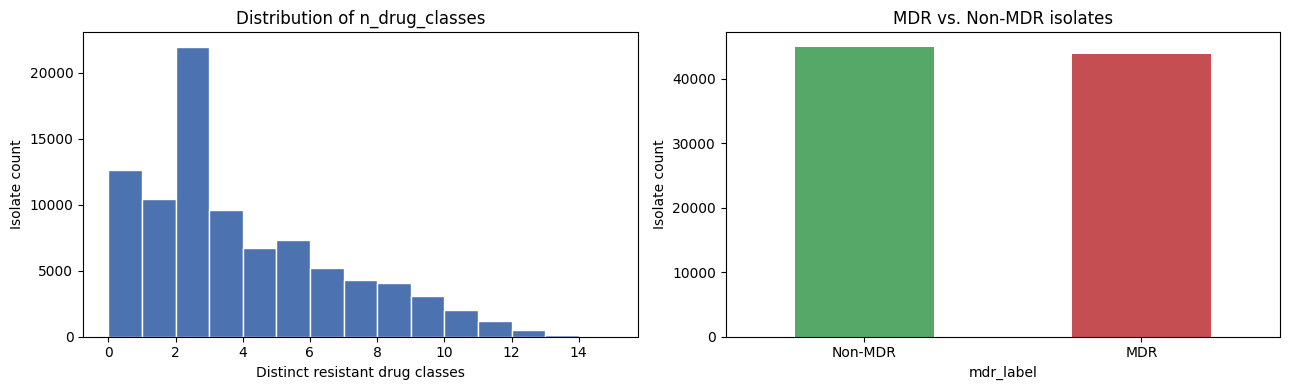

count    88837.000000
mean         3.457174
std          2.888646
min          0.000000
25%          1.000000
50%          2.000000
75%          5.000000
max         14.000000
Name: n_drug_classes, dtype: float64

mdr_label
0    0.506
1    0.494
Name: proportion, dtype: float64


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(model_df['n_drug_classes'], bins=range(0, 16), color='#4C72B0', edgecolor='white')
axes[0].set_title('Distribution of n_drug_classes')
axes[0].set_xlabel('Distinct resistant drug classes')
axes[0].set_ylabel('Isolate count')

model_df['mdr_label'].map({0: 'Non-MDR', 1: 'MDR'}).value_counts().plot(
    kind='bar', ax=axes[1], color=['#55A868', '#C44E52'])
axes[1].set_title('MDR vs. Non-MDR isolates')
axes[1].set_ylabel('Isolate count')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

print(model_df['n_drug_classes'].describe())
print()
print(model_df['mdr_label'].value_counts(normalize=True).round(3))




**Finding:** `n_drug_classes` is spread across the full 0–14 range rather than
concentrated at one value, and `mdr_label` is close to balanced (~51% / 49%) —
good for modelling, since a heavily imbalanced target usually needs
extra handling (resampling, class weights) that a balanced one doesn't.

# 5 — Exploratory Data Analysis

---
## 5.1 Univariate Analysis

Looking at each predictor feature on its own, before comparing any of them to the
target.

### 5.11 Categorical features — bar charts

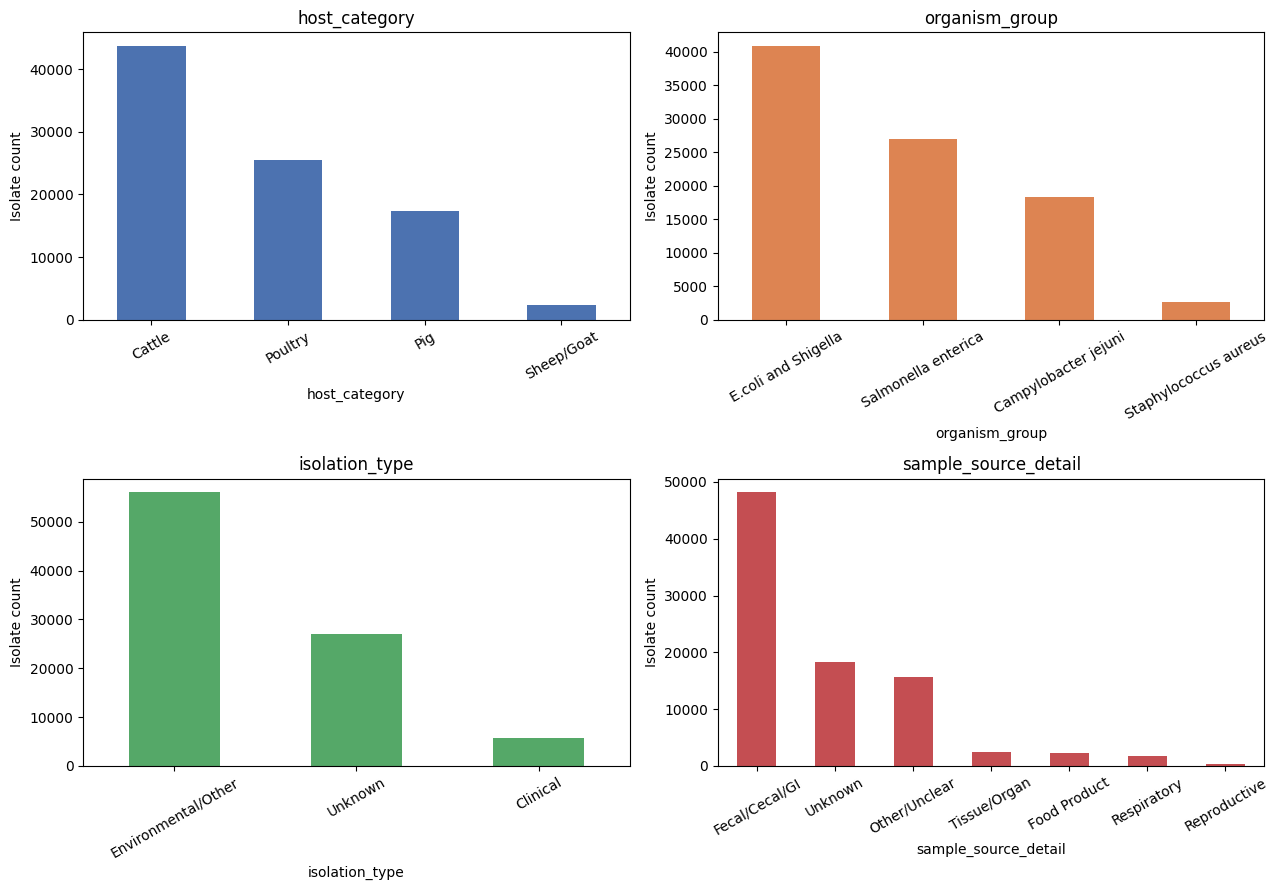

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

cat_plots = ['host_category', 'organism_group', 'isolation_type', 'sample_source_detail']
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

for ax, col, color in zip(axes.flat, cat_plots, colors):
    model_df[col].value_counts().plot(kind='bar', ax=ax, color=color)
    ax.set_title(col)
    ax.set_ylabel('Isolate count')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()



### 5.12 Country — bar chart & treemap

`country` has 14 categories with very uneven sizes (USA alone is roughly half the dataset) — a bar chart works, but a **treemap** shows the relative *proportion* of each country more intuitively, since box area directly represents share of the whole.


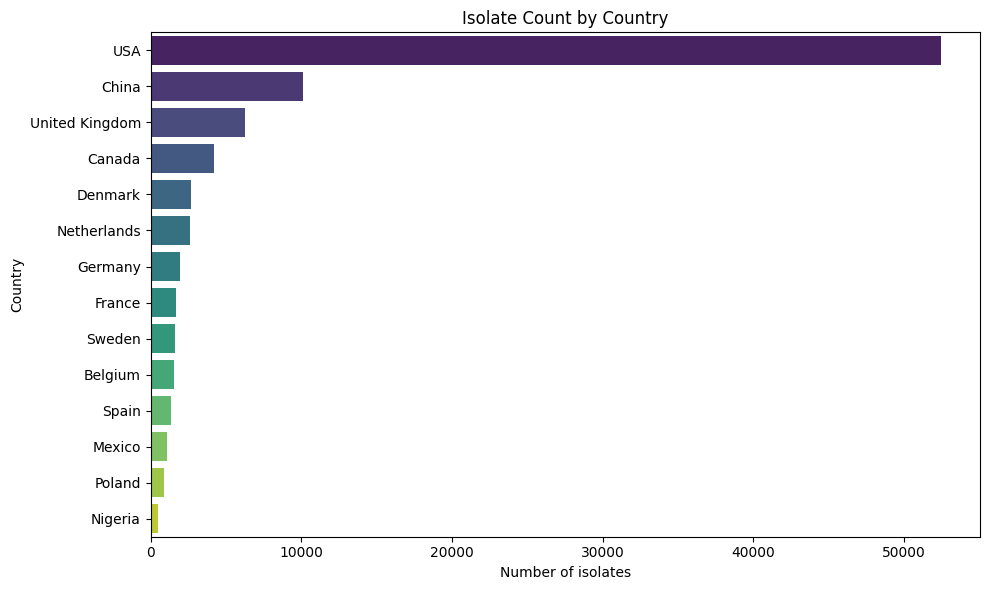

In [24]:
country_counts = model_df['country'].value_counts().head(20)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_counts.values,
    y=country_counts.index,
    hue=country_counts.index,
    palette="viridis",
    dodge=False,
    legend=False
)

plt.xlabel("Number of isolates")
plt.ylabel("Country")
plt.title("Isolate Count by Country")

plt.tight_layout()
plt.show()

In [25]:
import plotly.express as px

country_counts = (
    model_df['country']
    .value_counts()
    .reset_index()
)

country_counts.columns = ['Country', 'Count']

fig = px.treemap(
    country_counts,
    path=['Country'],
    values='Count',
    color='Count',
    color_continuous_scale='Viridis'
)

fig.update_layout(
    title='Isolate Count by Country',
    margin=dict(t=50, l=20, r=20, b=20)
)

fig.show()

### 5.13 Numeric features — histograms

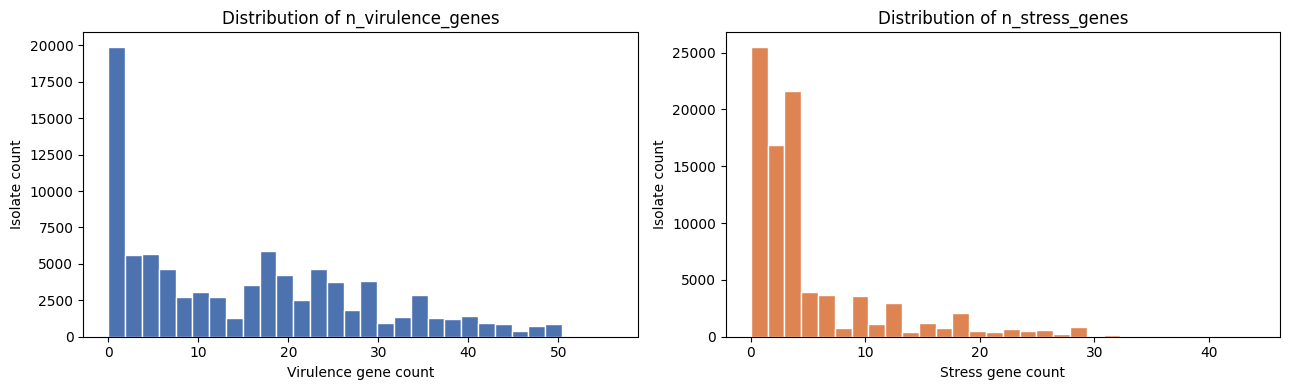

,year,n_virulence_genes,n_stress_genes
count,88837.000000,88837.000000,88837.000000
mean,2021.432117,15.032149,4.965555
std,2.887254,13.415055,6.233311
min,2011.000000,0.000000,0.000000
25%,2019.000000,2.000000,1.000000
50%,2022.000000,14.000000,3.000000
75%,2024.000000,25.000000,5.000000
max,2026.000000,56.000000,44.000000


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(model_df['n_virulence_genes'], bins=30, color='#4C72B0', edgecolor='white')
axes[0].set_title('Distribution of n_virulence_genes')
axes[0].set_xlabel('Virulence gene count')
axes[0].set_ylabel('Isolate count')

axes[1].hist(model_df['n_stress_genes'], bins=30, color='#DD8452', edgecolor='white')
axes[1].set_title('Distribution of n_stress_genes')
axes[1].set_xlabel('Stress gene count')
axes[1].set_ylabel('Isolate count')

plt.tight_layout()
plt.show()

model_df[['year', 'n_virulence_genes', 'n_stress_genes']].describe()


**Findings:** `host_category` is dominated by Cattle and Poultry; `USA` alone
accounts for roughly half of all isolates (clear in the treemap) — this imbalance is
worth remembering when interpreting any country-level pattern later, since a rare
country's stats rest on a much smaller sample. `n_virulence_genes` and
`n_stress_genes` are both right-skewed with a long tail — most isolates carry a
modest number of genes, a smaller number carry many.

---
## 5.2 Bivariate Analysis

Now comparing predictor features against the target, to see which ones actually
carry a relationship worth modelling.

### 5.21 MDR rate by categorical feature

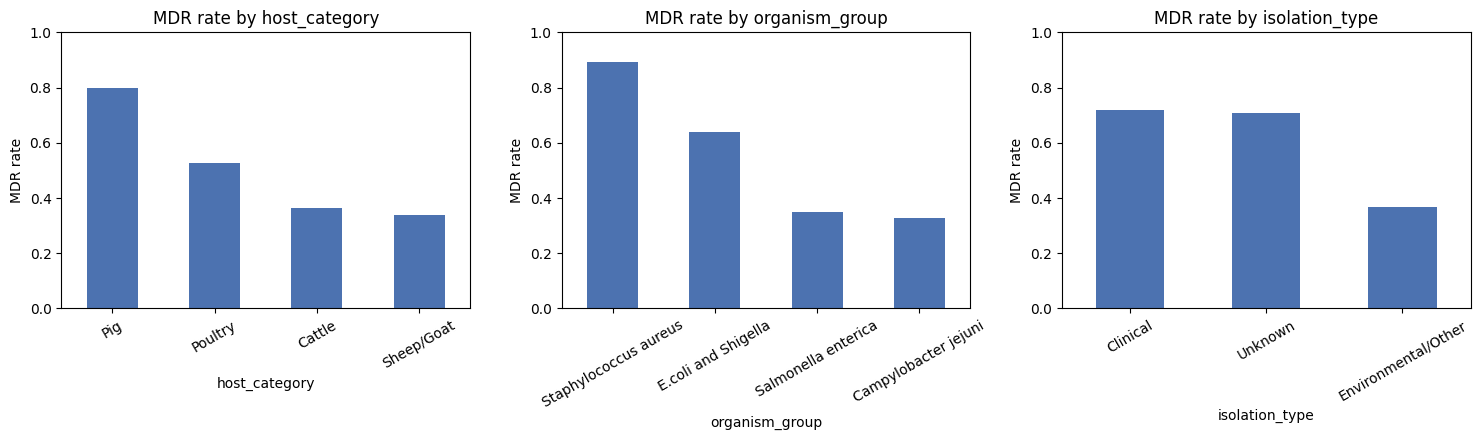

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col in zip(axes, ['host_category', 'organism_group', 'isolation_type']):
    rate = model_df.groupby(col)['mdr_label'].mean().sort_values(ascending=False)
    rate.plot(kind='bar', ax=ax, color='#4C72B0')
    ax.set_title(f'MDR rate by {col}')
    ax.set_ylabel('MDR rate')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


**Sampling-bias check:** `isolation_type` (Clinical vs. Environmental/Other) shows a
visible MDR-rate gap. This matters for interpretation — clinical isolates come from
animals that were already sick, often *after* antibiotic treatment, so a higher
clinical MDR rate reflects **which animals get sampled**, not that "resistance is
rising in sick animals." Worth stating this caveat directly in the report rather than
over-interpreting the gap.

In [28]:
print(model_df.groupby('isolation_type')['mdr_label'].agg(['mean', 'count']))


                         mean  count
isolation_type                      
Clinical             0.717133   5720
Environmental/Other  0.368631  56056
Unknown              0.706293  27061


### 5.22 Numeric feature vs. binary target — boxplot

A boxplot is a good fit here: comparing the full distribution of a numeric feature
(`n_stress_genes`) across the two `mdr_label` groups, not just their averages.

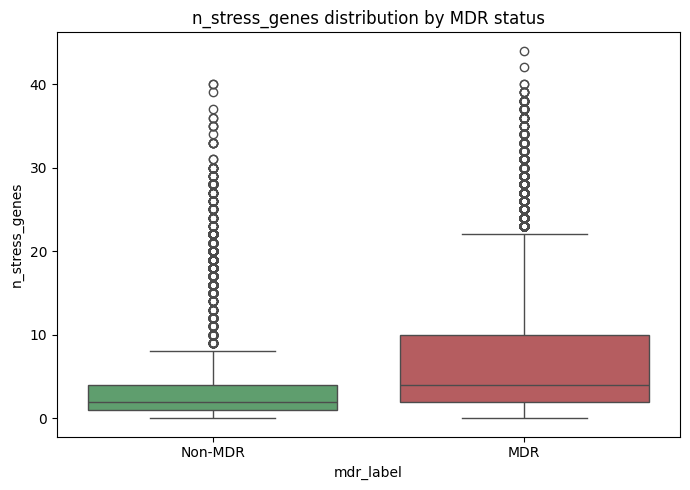

In [29]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(data=model_df, x='mdr_label', y='n_stress_genes', ax=ax,
            hue='mdr_label', palette=['#55A868', '#C44E52'], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Non-MDR', 'MDR'])
ax.set_title('n_stress_genes distribution by MDR status')

plt.tight_layout()
plt.show()


### 5.23 Core hypothesis check — gene counts vs. resistance burden (line chart)

Do `n_virulence_genes` / `n_stress_genes` actually track `n_drug_classes`? This is
the central assumption behind the whole modelling approach, so it's worth checking
directly rather than assuming it from the boxplot alone.

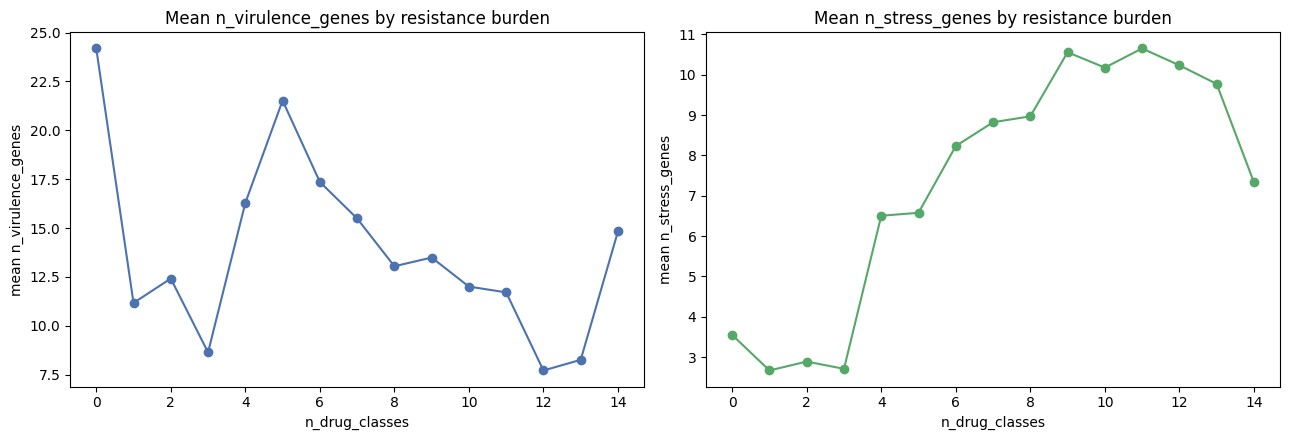

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, col, color in zip(axes, ['n_virulence_genes', 'n_stress_genes'], ['#4C72B0', '#55A868']):
    mean_by_burden = model_df.groupby('n_drug_classes')[col].mean()
    ax.plot(mean_by_burden.index, mean_by_burden.values, marker='o', color=color)
    ax.set_xlabel('n_drug_classes')
    ax.set_ylabel(f'mean {col}')
    ax.set_title(f'Mean {col} by resistance burden')

plt.tight_layout()
plt.show()


### 5.24 Trend over time (line chart)

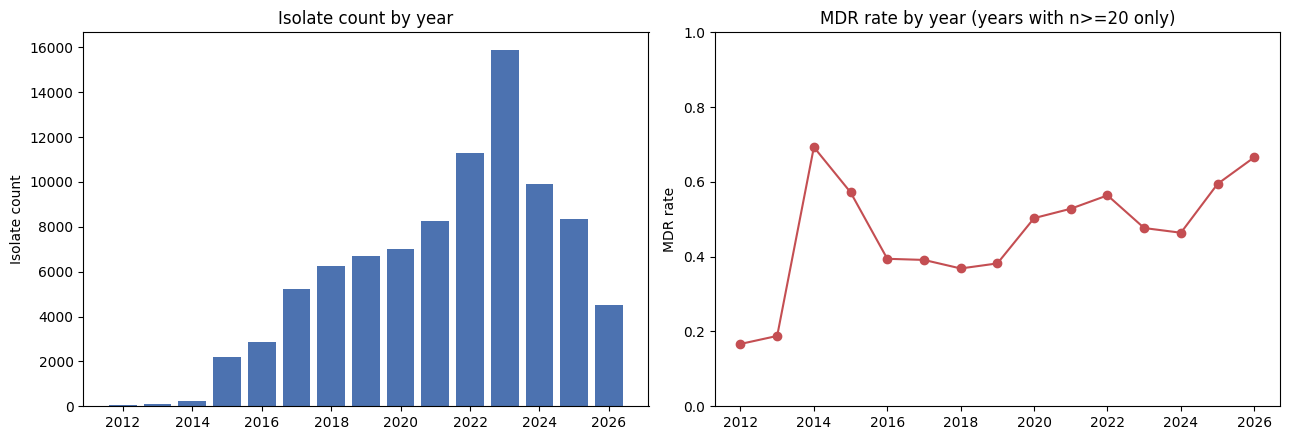

In [31]:
yearly = model_df.groupby('year').agg(n_isolates=('BioSample', 'count'),
                                         mdr_rate=('mdr_label', 'mean'))
yearly = yearly[yearly['n_isolates'] >= 20]  # drop very sparse edge years

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(yearly.index, yearly['n_isolates'], color='#4C72B0')
axes[0].set_title('Isolate count by year')
axes[0].set_ylabel('Isolate count')

axes[1].plot(yearly.index, yearly['mdr_rate'], marker='o', color='#C44E52')
axes[1].set_title('MDR rate by year (years with n>=20 only)')
axes[1].set_ylabel('MDR rate')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()


**Findings:** the `isolation_type` MDR gap confirms the sampling-bias risk is real
in this dataset, not just a theoretical concern. Host and organism both show visible
MDR-rate differences worth carrying into modelling. Isolate volume by year is uneven
(a data-availability artifact, not an epidemiological pattern), so any year-on-year
MDR trend should be read cautiously.

---
## 5.3 Correlation Analysis

`year` is included in this correlation check deliberately, as a confounder test: if `year` (which mostly reflects when a record was submitted, not a real biological trend) turned out to correlate strongly with `n_drug_classes`, that would signal a data artifact -- e.g. different countries or organisms being concentrated in different years -- rather than genuine resistance-burden signal. Checking this now, before Phase 2 modelling, is cheaper than discovering it later as an unexplained "time leak" in a trained model.

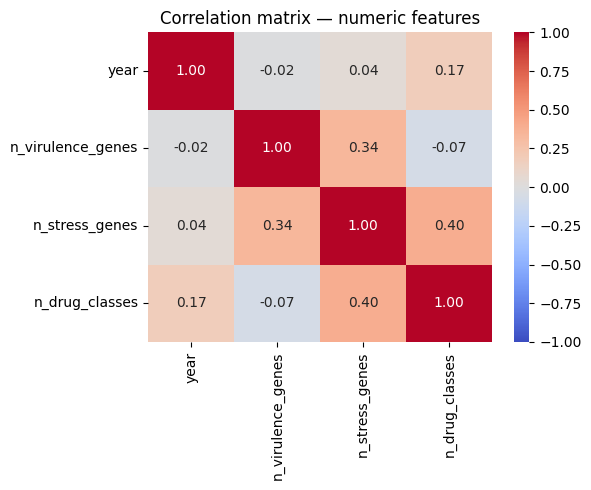

In [32]:
numeric_cols = ['year', 'n_virulence_genes', 'n_stress_genes', 'n_drug_classes']
corr_matrix = model_df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation matrix — numeric features')
plt.tight_layout()
plt.show()


**Finding:** `n_stress_genes` correlates moderately with `n_drug_classes`
(supports the co-selection hypothesis discussed in Part 1 — metal/biocide resistance genes tend to sit on the same mobile genetic elements as AMR genes). `n_virulence_genes` shows close to **no** linear correlation with resistance burden. It means the virulence gene count is a weaker predictor than originally hypothesised, while the stress gene count carries real signal. `year` shows negligible correlation with either target, which makes sense given it mostly reflects submission timing rather than a true resistance trend.

---
## 5.4 Outlier Investigation

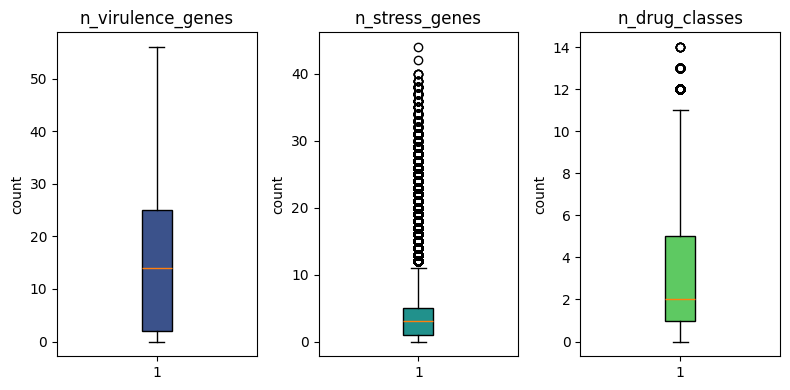

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(8, 4))
cols = ['n_virulence_genes', 'n_stress_genes', 'n_drug_classes']
colors = sns.color_palette("viridis", len(cols)) # Get a list of colors from viridis palette

for i, (ax, col) in enumerate(zip(axes, cols)):
    bp = ax.boxplot(model_df[col], vert=True, patch_artist=True) # patch_artist=True is key
    for box in bp['boxes']:
        box.set(facecolor=colors[i]) # Set the face color of the box
    ax.set_title(col)
    ax.set_ylabel('count')

plt.tight_layout()
plt.show()

In [34]:
def iqr_outlier_summary(series, name):
    """Print how many values fall outside the standard 1.5xIQR outlier fence."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((series < lower) | (series > upper)).sum()
    print(f'{name}: normal range=[{lower:.1f}, {upper:.1f}], '
          f'outliers={n_outliers} ({n_outliers/len(series)*100:.1f}%)')

for col in ['n_virulence_genes', 'n_stress_genes', 'n_drug_classes']:
    iqr_outlier_summary(model_df[col], col)


n_virulence_genes: normal range=[-32.5, 59.5], outliers=0 (0.0%)
n_stress_genes: normal range=[-5.0, 11.0], outliers=11695 (13.2%)
n_drug_classes: normal range=[-5.0, 11.0], outliers=560 (0.6%)


**Decision: outliers are kept, not removed.** An isolate carrying an unusually
high number of virulence or stress genes is a real biological signal (e.g. a
hypervirulent strain, or one under heavy metal/biocide selection pressure). This is directly relevant to the question this project is trying to answer, not measurement error. Removing these rows would throw away some of the most informative isolates in the dataset.

---


# 6 — Data Transformation (Categorical Encoding)

Machine learning models need numbers, not text -- so categorical columns need to be converted. This is done in three steps of increasing detail:

**6.1 Low-cardinality columns** (organism, host, isolation type, sample source, country) -- straightforward one-hot encoding, each category becomes its own 0/1 column.

**6.2 SNP cluster** -- too high-cardinality (12,353 unique values) to one-hot encode directly without creating thousands of mostly-empty columns. Instead, the top 50 most frequent clusters each get their own column, and everything else is grouped into a single `Minor/Other` bucket.

**6.3 Gene presence/absence bins** -- beyond the simple gene *counts* (`n_virulence_genes`, `n_stress_genes`), we add binary indicator columns for the top 100 most frequent virulence genes and top 50 most frequent stress genes individually. This lets the model learn that a *specific* gene matters, not just how many genes an isolate has -- e.g. one particular virulence gene might correlate with resistance burden even if the overall count doesn't.

In [35]:
low_cardinality_cols = ['organism_group', 'host_category', 'isolation_type',
                          'sample_source_detail', 'country']

for col in low_cardinality_cols:
    print(f'{col}: {model_df[col].nunique()} categories')

print()
print(f"SNP cluster: {model_df['SNP cluster'].nunique()} categories (kept aside — too high-cardinality)")


organism_group: 4 categories
host_category: 4 categories
isolation_type: 3 categories
sample_source_detail: 7 categories
country: 14 categories

SNP cluster: 12353 categories (kept aside — too high-cardinality)


High cardnality means that there are many distinct categories in a categorical variable.

## 6.1 Low-cardinality categorical columns

In [36]:
model_df_encoded = pd.get_dummies(model_df, columns=low_cardinality_cols, drop_first=False)

print('Shape before encoding:', model_df.shape)
print('Shape after encoding :', model_df_encoded.shape)
model_df_encoded.head()


Shape before encoding: (88837, 12)
Shape after encoding : (88837, 39)


,year,n_virulence_genes,n_stress_genes,SNP cluster,n_drug_classes,mdr_label,BioSample,organism_group_Campylobacter jejuni,organism_group_E.coli and Shigella,organism_group_Salmonella enterica,organism_group_Staphylococcus aureus,host_category_Cattle,host_category_Pig,host_category_Poultry,host_category_Sheep/Goat,isolation_type_Clinical,isolation_type_Environmental/Other,isolation_type_Unknown,sample_source_detail_Fecal/Cecal/GI,sample_source_detail_Food Product,sample_source_detail_Other/Unclear,sample_source_detail_Reproductive,sample_source_detail_Respiratory,sample_source_detail_Tissue/Organ,sample_source_detail_Unknown,country_Belgium,country_Canada,country_China,country_Denmark,country_France,country_Germany,country_Mexico,country_Netherlands,country_Nigeria,country_Poland,country_Spain,country_Sweden,country_USA,country_United Kingdom
0,2015,21,3,PDS000029314.465,0,0,SAMN01920794,False,False,True,False,True,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
1,2015,36,11,PDS000028886.33,6,1,SAMN01920795,False,False,True,False,True,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
2,2015,33,4,PDS000031449.1,0,0,SAMN01920796,False,False,True,False,True,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
3,2015,18,4,PDS000028048.426,1,0,SAMN01920797,False,False,True,False,True,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
4,2015,20,4,PDS000028126.23,2,0,SAMN01920798,False,False,True,False,True,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False


## 6.2 SNP cluster -- top 50 + Minor/Other

Rather than leaving `SNP cluster` out entirely, we keep the 50 most frequent clusters as their own categories (including `Unclustered`, which -- at 22,271 isolates -- is itself the single largest "cluster", so it earns its own column naturally rather than needing special-casing). Every other, rarer cluster is grouped into one `Minor/Other` column.

In [37]:
TOP_N_SNP = 50

snp_counts = model_df_encoded['SNP cluster'].value_counts()
top_snp_clusters = set(snp_counts.head(TOP_N_SNP).index)

# Any cluster not in the top 50 gets grouped into a single 'Minor/Other' bucket
model_df_encoded['snp_cluster_grouped'] = model_df_encoded['SNP cluster'].apply(
    lambda cluster: cluster if cluster in top_snp_clusters else 'Minor/Other'
)

model_df_encoded = pd.get_dummies(model_df_encoded, columns=['snp_cluster_grouped'], drop_first=False)
model_df_encoded = model_df_encoded.drop(columns=['SNP cluster'])  # replaced by the dummies above

print(f'SNP cluster encoded into {len(top_snp_clusters)} top clusters + 1 Minor/Other bucket')
print('Shape after SNP cluster encoding:', model_df_encoded.shape)


SNP cluster encoded into 50 top clusters + 1 Minor/Other bucket
Shape after SNP cluster encoding: (88837, 89)


## 6.3 Gene presence/absence bins (top 100 virulence, top 50 stress)

We go back to the parsed gene lists from section 4 (`vir_gene_list`, `stress_gene_list` in `df`) -- these aren't in `model_df` itself, but `df` and `model_df` share the same row index, so we can pull them back in by index alignment.

`MultiLabelBinarizer` turns each isolate's gene list into a row of 0/1 flags, one column per gene. We restrict to the top 100 virulence / top 50 stress genes by frequency (out of 251 and 83 unique genes respectively) -- the rarer genes are already captured in aggregate by the `n_virulence_genes` / `n_stress_genes` counts, so nothing is lost, and it keeps the feature matrix from ballooning further.

In [38]:
from sklearn.preprocessing import MultiLabelBinarizer
from collections import Counter

TOP_N_VIRULENCE = 100
TOP_N_STRESS = 50

# Pull the parsed gene lists back in from df, aligned by row index
vir_lists = df.loc[model_df_encoded.index, 'vir_gene_list']
stress_lists = df.loc[model_df_encoded.index, 'stress_gene_list']

# Count how often each gene appears across our modelling population, then keep the top N
vir_gene_counts = Counter(gene for gene_list in vir_lists for gene in gene_list)
stress_gene_counts = Counter(gene for gene_list in stress_lists for gene in gene_list)

top_vir_genes = [gene for gene, _ in vir_gene_counts.most_common(TOP_N_VIRULENCE)]
top_stress_genes = [gene for gene, _ in stress_gene_counts.most_common(TOP_N_STRESS)]

# Drop any gene not in our top-N list before binarizing (keeps the matrix to exactly
# TOP_N_VIRULENCE / TOP_N_STRESS columns, rather than one column per unique gene)
vir_lists_top = vir_lists.apply(lambda genes: [g for g in genes if g in top_vir_genes])
stress_lists_top = stress_lists.apply(lambda genes: [g for g in genes if g in top_stress_genes])

mlb_vir = MultiLabelBinarizer(classes=top_vir_genes)
vir_gene_matrix = mlb_vir.fit_transform(vir_lists_top)
vir_gene_df = pd.DataFrame(vir_gene_matrix, columns=[f'vir_gene_{g}' for g in mlb_vir.classes_],
                            index=model_df_encoded.index)

mlb_stress = MultiLabelBinarizer(classes=top_stress_genes)
stress_gene_matrix = mlb_stress.fit_transform(stress_lists_top)
stress_gene_df = pd.DataFrame(stress_gene_matrix, columns=[f'stress_gene_{g}' for g in mlb_stress.classes_],
                               index=model_df_encoded.index)

model_df_encoded = pd.concat([model_df_encoded, vir_gene_df, stress_gene_df], axis=1)

print(f'Added {vir_gene_df.shape[1]} virulence-gene presence columns '
      f'and {stress_gene_df.shape[1]} stress-gene presence columns')
print('Final encoded shape:', model_df_encoded.shape)


Added 100 virulence-gene presence columns and 50 stress-gene presence columns
Final encoded shape: (88837, 239)


# 7 — Data Preprocessing

---
## 7.1 Split into Train/Test

Splitting **before** any scaling or imputing happens (Parts 14–15) is important: if
we calculated scaling statistics (like the mean/standard deviation) using the full
dataset and then split, information from the test set would "leak" into training —
the model would get an unfairly easy preview of data it's supposed to be evaluated
on later. `stratify=y` keeps the MDR/non-MDR ratio consistent across both sets.

In [39]:
from sklearn.model_selection import train_test_split

# Columns we don't want to feed into a model directly
# 'SNP cluster' no longer needs excluding here -- it was already replaced by
# its one-hot encoded columns in Part 12.2, so it no longer exists as a raw column
non_feature_cols = ['BioSample', 'n_drug_classes', 'mdr_label']

X = model_df_encoded.drop(columns=non_feature_cols)
y = model_df_encoded['mdr_label']   # classification target (regression target n_drug_classes also available)

# Stratify on BOTH mdr_label and organism_group together, so the split preserves
# the balance of each organism within each MDR class, not just overall MDR balance.
# organism_group was one-hot encoded in Part 12, so we rebuild the combined key from
# model_df (which still has the plain categorical column) aligned by row index.
stratify_key = model_df.loc[X.index, 'organism_group'] + '_' + y.astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=stratify_key
)

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print()
print('MDR rate in training set:', y_train.mean().round(3))
print('MDR rate in test set    :', y_test.mean().round(3))


X_train: (71069, 236) | X_test: (17768, 236)

MDR rate in training set: 0.494
MDR rate in test set    : 0.494


---
## 7.2 Fit Imputer/Scaler on Training Data

Two notes before this step:

1. **No imputer is strictly required here** — every missing value was already
   resolved with a domain-specific rule back in Part 4/6 (e.g. missing gene data →  0 genes, missing sample type → `'Unknown'` category), rather than being left as `NaN` for a generic imputer to guess at. A `SimpleImputer` is still demonstrated below for completeness / good habit, but it should find nothing to do.
   
2. **Scaling will be dependant on the model choice for assignment 2** — tree-based models like CatBoost/XGBoost don't need scaled features, but it's good practice to have a properly-fit scaler ready in case a distance-based or linear model is tried too.

Both are **fit on `X_train` only**, never on `X_test` — fitting means "learn the
mean/median/std from this data," and that learning must never see the test set.

In [40]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_cols = ['year', 'n_virulence_genes', 'n_stress_genes']

imputer = SimpleImputer(strategy='median')
imputer.fit(X_train[numeric_cols])   # learns median from TRAINING data only

scaler = StandardScaler()
scaler.fit(X_train[numeric_cols])    # learns mean/std from TRAINING data only

print('Imputer learned medians:', dict(zip(numeric_cols, imputer.statistics_)))
print('Scaler learned means   :', dict(zip(numeric_cols, scaler.mean_.round(2))))


Imputer learned medians: {'year': np.float64(2022.0), 'n_virulence_genes': np.float64(14.0), 'n_stress_genes': np.float64(3.0)}
Scaler learned means   : {'year': np.float64(2021.42), 'n_virulence_genes': np.float64(15.04), 'n_stress_genes': np.float64(4.97)}


---
## 7.3 Transform Training and Test Data

Now we **apply** (not re-fit) the imputer and scaler to both sets. `X_test` uses the
statistics learned from `X_train` — this is what keeps the split leakage-free.

In [41]:
X_train_final = X_train.copy()
X_test_final = X_test.copy()

X_train_final[numeric_cols] = imputer.transform(X_train[numeric_cols])
X_test_final[numeric_cols] = imputer.transform(X_test[numeric_cols])

X_train_final[numeric_cols] = scaler.transform(X_train_final[numeric_cols])
X_test_final[numeric_cols] = scaler.transform(X_test_final[numeric_cols])

print('Scaled training data — numeric columns now have mean ~0, std ~1:')
X_train_final[numeric_cols].describe().round(2)


Scaled training data — numeric columns now have mean ~0, std ~1:


,year,n_virulence_genes,n_stress_genes
count,71069.00,71069.00,71069.00
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-3.61,-1.12,-0.80
25%,-0.84,-0.97,-0.64
50%,0.20,-0.08,-0.31
75%,0.89,0.74,0.01
max,1.59,2.90,6.25


---
# 8 — Saved Outputs
For the next assignment, I have the following ready: the cleaned table, the encoded table, and the already-split/scaled train/test sets.

In [42]:
model_df.to_csv('amr_livestock_features_clean.csv', index=False)
model_df_encoded.to_csv('amr_livestock_features_encoded.csv', index=False)

X_train_final.to_csv('X_train.csv', index=False)
X_test_final.to_csv('X_test.csv', index=False)
y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

print('Saved:')
print(' - amr_livestock_features_clean.csv    (human-readable, full modelling table)')
print(' - amr_livestock_features_encoded.csv  (one-hot encoded, full table)')
print(' - X_train.csv / X_test.csv            (scaled features, split, leakage-free)')
print(' - y_train.csv / y_test.csv            (MDR labels, matching split)')


Saved:
 - amr_livestock_features_clean.csv    (human-readable, full modelling table)
 - amr_livestock_features_encoded.csv  (one-hot encoded, full table)
 - X_train.csv / X_test.csv            (scaled features, split, leakage-free)
 - y_train.csv / y_test.csv            (MDR labels, matching split)


In [43]:
unique_organisms = model_df['organism_group'].unique()
print(f'{len(unique_organisms)} unique organisms:')
print(unique_organisms)

# With counts, for context
print()
print(model_df['organism_group'].value_counts())

4 unique organisms:
['Salmonella enterica' 'Campylobacter jejuni' 'E.coli and Shigella'
 'Staphylococcus aureus']

organism_group
E.coli and Shigella      40888
Salmonella enterica      27036
Campylobacter jejuni     18280
Staphylococcus aureus     2633
Name: count, dtype: int64


# 9 — Summary

- The modelling table is clean, leakage-free, and the MDR target is close to
  balanced (~51/49), reducing the need for resampling in assignment 2.
- Host, organism, and isolation-type all show visible MDR-rate differences
- `n_stress_genes` (not `n_virulence_genes`) is the stronger correlate of resistance burden — the key EDA result even though it partially challenges the original hypothesis.
- High-cardinality features, such as SNP cluster, will be handled using CatBoost or XGBoost as baseline models. As an extension, a Graph Neural Network (GNN) will be investigated to directly capture gene co-occurrence and phylogenetic relatedness, aligning with the original proposal.


# **ASSIGNMENT 2 —  ML & AI +Masters: Model Training, Evaluation and Analysis**

---

This notebook continues directly from **Assignment 1 / Phase 1**.

Phase 1 produced the cleaned modelling table and the encoded feature matrix. Phase 2
answers the predictive questions in a controlled sequence:

> **Validate the target → create a fixed train/validation/test split → select models →
> tune promising models → lock the final candidates → evaluate once on the test set →
> interpret the selected model → model resistance burden as a regression problem →
> investigate gene co-occurrence structure → test a GNN → compare the approaches →
> draw conclusions.**

The held-out test set is treated as **locked**: it is not used to choose models,
hyperparameters, or the final model family.

# **Table of Contents**

### 1. Setup and Data Loading
### 2. Target Validation and Data Quality
- 2.1 AST validation of the genotype-derived target
- 2.2 Target distribution and class balance
- 2.3 Evaluation strategy

### 3. Train / Validation / Test Split
- 3.1 Define targets and predictors
- 3.2 Stratified 70/15/15 split
- 3.3 Verify the split
- 3.4 Fit preprocessing on training data only

### 4. Classification — Model Selection and Baselines
- 4.1 Candidate models
- 4.2 Baseline training
- 4.3 Validation comparison

### 5. Classification — Hyperparameter Tuning
- 5.1 Random Forest
- 5.2 HistGradientBoosting
- 5.3 XGBoost and CatBoost
- 5.4 Validation comparison after tuning

### 6. Classification — Final Model Selection
- 6.1 Select using validation performance
- 6.2 Lock the final candidates

### 7. Classification — Final Test Evaluation
- 7.1 Test-set metrics
- 7.2 ROC curves
- 7.3 Confusion matrix and classification report
- 7.4 Error analysis

### 8. Classification — Interpretability
- 8.1 Feature importance
- 8.2 Grouped feature importance
- 8.3 Biological interpretation

### 9. Regression — `n_drug_classes`
- 9.1 Regression model selection
- 9.2 Final test evaluation
- 9.3 Residual analysis

### 10. Gene Co-occurrence Network
- 10.1 Descriptive network construction
- 10.2 Hub genes
- 10.3 Network visualisation
- 10.4 Predictive graph feature using a training-only graph

### 11. Graph Neural Network
- 11.1 Motivation
- 11.2 Training-only graph construction
- 11.3 Isolate-level graph datasets
- 11.4 Weighted GCN
- 11.5 Early stopping and validation
- 11.6 Test evaluation
- 11.7 Gene-set ablation
- 11.8 GNN vs Random Forest on the same test isolates

### 12. Overall Results
### 13. Conclusions

---
# 1 — Setup and Data Loading

Assignment 2 uses the outputs saved by Phase 1:

- `amr_livestock_features_clean.csv`
- `amr_livestock_features_encoded.csv`

The raw NCBI file is reloaded only when needed for the AST validation and
gene-network sections because those fields were deliberately not carried into
the Phase 1 modelling matrix.

In [44]:
# Core imports
import pandas as pd
import numpy as np
import warnings
import time
import os

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
    RandomForestRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [45]:
# Phase 1 outputs
CLEAN_PATH = "amr_livestock_features_clean.csv"
ENCODED_PATH = "amr_livestock_features_encoded.csv"

if not os.path.exists(CLEAN_PATH) or not os.path.exists(ENCODED_PATH):
    raise FileNotFoundError(
        "Phase 1 outputs were not found. Run Assignment 1 first so that "
        f"{CLEAN_PATH!r} and {ENCODED_PATH!r} are available."
    )

clean = pd.read_csv(CLEAN_PATH)
encoded = pd.read_csv(ENCODED_PATH)

# Keep the two tables aligned by the stable isolate identifier.
if clean["BioSample"].duplicated().any() or encoded["BioSample"].duplicated().any():
    raise ValueError("BioSample must be unique in both Phase 1 outputs.")

clean = clean.set_index("BioSample").loc[encoded["BioSample"]].reset_index()

print("Clean table shape   :", clean.shape)
print("Encoded table shape :", encoded.shape)
print("Unique BioSamples    :", encoded["BioSample"].nunique())
print("MDR prevalence       :", round(encoded["mdr_label"].mean(), 3))
print("Drug-class range     :", int(encoded["n_drug_classes"].min()), "to", int(encoded["n_drug_classes"].max()))

display(encoded.head(3))

Clean table shape   : (88837, 12)
Encoded table shape : (88837, 239)
Unique BioSamples    : 88837
MDR prevalence       : 0.494
Drug-class range     : 0 to 14


,year,n_virulence_genes,n_stress_genes,n_drug_classes,mdr_label,BioSample,organism_group_Campylobacter jejuni,organism_group_E.coli and Shigella,organism_group_Salmonella enterica,organism_group_Staphylococcus aureus,host_category_Cattle,host_category_Pig,host_category_Poultry,host_category_Sheep/Goat,isolation_type_Clinical,isolation_type_Environmental/Other,isolation_type_Unknown,sample_source_detail_Fecal/Cecal/GI,sample_source_detail_Food Product,sample_source_detail_Other/Unclear,sample_source_detail_Reproductive,sample_source_detail_Respiratory,sample_source_detail_Tissue/Organ,sample_source_detail_Unknown,country_Belgium,country_Canada,country_China,country_Denmark,country_France,country_Germany,country_Mexico,country_Netherlands,country_Nigeria,country_Poland,country_Spain,country_Sweden,country_USA,country_United Kingdom,snp_cluster_grouped_Minor/Other,snp_cluster_grouped_PDS000002079.115,snp_cluster_grouped_PDS000002218.1055,snp_cluster_grouped_PDS000002504.658,snp_cluster_grouped_PDS000004170.793,snp_cluster_grouped_PDS000013650.294,snp_cluster_grouped_PDS000019951.34,snp_cluster_grouped_PDS000022084.101,snp_cluster_grouped_PDS000022633.264,snp_cluster_grouped_PDS000022832.251,snp_cluster_grouped_PDS000026541.361,snp_cluster_grouped_PDS000026869.655,...,stress_gene_ariR,stress_gene_golT,stress_gene_golS,stress_gene_emrE,stress_gene_asr,stress_gene_merR,stress_gene_merP,stress_gene_merT,stress_gene_terD,stress_gene_terW,stress_gene_terZ,stress_gene_qacEdelta1,stress_gene_merC,stress_gene_arsD,stress_gene_merD,stress_gene_merE,stress_gene_merA,stress_gene_silC,stress_gene_silA,stress_gene_silB,stress_gene_silR,stress_gene_silS,stress_gene_silF,stress_gene_silE,stress_gene_silP,stress_gene_pcoA,stress_gene_pcoS,stress_gene_pcoC,stress_gene_pcoR,stress_gene_pcoD,stress_gene_acr3,stress_gene_pcoB,stress_gene_pcoE,stress_gene_arsR,stress_gene_qacL,stress_gene_arsB,stress_gene_arsP,stress_gene_arsC,stress_gene_lmrS,stress_gene_arsA,stress_gene_merB,stress_gene_qacE,stress_gene_mco,stress_gene_clpK,stress_gene_trxLHR,stress_gene_psi-GI,stress_gene_hsp20,stress_gene_kefB-GI,stress_gene_cadD,stress_gene_qacG2
0,2015,21,3,0,0,SAMN01920794,False,False,True,False,True,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,...,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2015,36,11,6,1,SAMN01920795,False,False,True,False,True,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,...,0,1,1,0,1,1,1,1,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
2,2015,33,4,0,0,SAMN01920796,False,False,True,False,True,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,...,0,1,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 1.1 Modelling objective

The primary task is **binary classification** of the genotype-derived `mdr_label`.

The secondary task is **regression** of `n_drug_classes`, which captures resistance
burden on a continuum rather than reducing it to a single MDR threshold.

A key distinction is retained throughout the notebook:

> The targets are **genotype-derived proxies**, not laboratory-confirmed phenotypes.

---
# 2 — Target Validation and Data Quality

---

## 2.1 AST validation of the genotype-derived target

`mdr_label` and `n_drug_classes` were constructed from resistance-gene presence.
Usable AST data were too sparse to use as the main training target, but the available
AST-labelled isolates provide an important independent check of whether the
genotype-derived target behaves like a phenotypic resistance measure.

This section therefore validates the **target definition**, rather than treating AST
as a second training dataset.

In [46]:
# Original NCBI source used in Phase 1
DATA_URL = "https://drive.google.com/uc?export=download&id=1PcBQAdPZgbfVG30TpnQDnICB2zdyFm6h"

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    df_raw_ast = pd.read_csv(DATA_URL, engine="python", on_bad_lines="skip")

df_raw_ast.columns = [c.lstrip("#") for c in df_raw_ast.columns]

ast_labeled = df_raw_ast[df_raw_ast["AST phenotypes"].notna()].copy()

print("Isolates with usable AST phenotype data:", len(ast_labeled))

Isolates with usable AST phenotype data: 1814


In [47]:
# Map AST antibiotic names to the same drug-class definitions used for the
# genotype-derived target in Phase 1.
ANTIBIOTIC_TO_CLASS = {
    "amikacin": "Aminoglycosides", "amoxicillin": "Beta-lactams",
    "amoxicillin-clavulanic acid": "Beta-lactams", "ampicillin": "Beta-lactams",
    "azithromycin": "Macrolides", "aztreonam": "Beta-lactams",
    "cefalotin": "Beta-lactams", "cefazolin": "Beta-lactams", "cefepime": "Beta-lactams",
    "cefotaxime": "Beta-lactams", "cefotaxime-clavulanic acid": "Beta-lactams",
    "cefoxitin": "Beta-lactams", "cefpodoxime": "Beta-lactams", "ceftazidime": "Beta-lactams",
    "ceftazidime-clavulanic acid": "Beta-lactams", "ceftiofur": "Beta-lactams",
    "ceftriaxone": "Beta-lactams", "cefuroxime": "Beta-lactams", "cephalothin": "Beta-lactams",
    "chloramphenicol": "Phenicols", "chlortetracycline": "Tetracyclines",
    "ciprofloxacin": "Quinolones", "clindamycin": "Lincosamides/Streptogramins",
    "colistin": "Colistin/Polymyxins", "danofloxacin": "Quinolones",
    "enrofloxacin": "Quinolones", "ertapenem": "Beta-lactams",
    "erythromycin": "Macrolides", "florfenicol": "Phenicols",
    "gentamicin": "Aminoglycosides", "imipenem": "Beta-lactams",
    "kanamycin": "Aminoglycosides", "meropenem": "Beta-lactams",
    "nalidixic acid": "Quinolones", "neomycin": "Aminoglycosides",
    "novobiocin": "Unclassified/Other", "oxytetracycline": "Tetracyclines",
    "penicillin": "Beta-lactams", "piperacillin": "Beta-lactams",
    "piperacillin-tazobactam": "Beta-lactams", "spectinomycin": "Aminoglycosides",
    "streptomycin": "Aminoglycosides", "sulfadimethoxine": "Sulfonamides",
    "sulfamethoxazole": "Sulfonamides", "sulfisoxazole": "Sulfonamides",
    "telithromycin": "Macrolides", "temocillin": "Beta-lactams",
    "tetracycline": "Tetracyclines", "tiamulin": "Unclassified/Other",
    "ticarcillin": "Beta-lactams", "ticarcillin-clavulanate": "Beta-lactams",
    "ticarcillin-clavulanic acid": "Beta-lactams", "tigecycline": "Tetracyclines",
    "tilmicosin": "Macrolides", "trimethoprim": "Trimethoprim",
    "trimethoprim-sulfamethoxazole": "Trimethoprim",
    "tulathromycin": "Macrolides", "tylosin": "Macrolides",
}

def parse_ast(ast_string):
    if pd.isna(ast_string):
        return {}
    result = {}
    for entry in str(ast_string).split(","):
        if "=" in entry:
            drug, call = entry.split("=", 1)
            result[drug.strip()] = call.strip()
    return result

def ast_drug_classes(ast_dict):
    classes = set()
    for drug, call in ast_dict.items():
        if call == "R":
            drug_class = ANTIBIOTIC_TO_CLASS.get(drug, "Unclassified/Other")
            if drug_class != "Unclassified/Other":
                classes.add(drug_class)
    return classes

ast_labeled["ast_dict"] = ast_labeled["AST phenotypes"].apply(parse_ast)
ast_labeled["n_drug_classes_ast"] = ast_labeled["ast_dict"].apply(
    lambda d: len(ast_drug_classes(d))
)
ast_labeled["mdr_label_ast"] = (ast_labeled["n_drug_classes_ast"] >= 3).astype(int)

validation_set = ast_labeled.merge(
    clean[["BioSample", "n_drug_classes", "mdr_label"]],
    on="BioSample",
    how="inner"
)

agreement = (validation_set["mdr_label"] == validation_set["mdr_label_ast"]).mean()
mae_ast = mean_absolute_error(
    validation_set["n_drug_classes_ast"],
    validation_set["n_drug_classes"]
)
corr_ast = validation_set["n_drug_classes"].corr(
    validation_set["n_drug_classes_ast"]
)

print("AST-labelled isolates available after the same livestock filtering:", len(validation_set))
print(f"MDR label agreement: {agreement:.1%}")
print(f"MAE for n_drug_classes: {mae_ast:.2f}")
print(f"Correlation for n_drug_classes: {corr_ast:.3f}")
print()
print("Confusion matrix (rows = AST, columns = genotype-derived):")
print(confusion_matrix(validation_set["mdr_label_ast"], validation_set["mdr_label"]))
print()
print(
    classification_report(
        validation_set["mdr_label_ast"],
        validation_set["mdr_label"],
        target_names=["Non-MDR (AST)", "MDR (AST)"]
    )
)

AST-labelled isolates available after the same livestock filtering: 1357
MDR label agreement: 77.9%
MAE for n_drug_classes: 1.31
Correlation for n_drug_classes: 0.929

Confusion matrix (rows = AST, columns = genotype-derived):
[[630 297]
 [  3 427]]

               precision    recall  f1-score   support

Non-MDR (AST)       1.00      0.68      0.81       927
    MDR (AST)       0.59      0.99      0.74       430

     accuracy                           0.78      1357
    macro avg       0.79      0.84      0.77      1357
 weighted avg       0.87      0.78      0.79      1357



### 2.1.1 Interpretation of the AST check

Agreement is 77.9% — meaningfully below the 95–99% figure from the literature we originally cited. The breakdown explains why: 99% recall, but only 59% precision for MDR. Our genotype-based target almost never misses a truly resistant isolate, but it substantially over-calls MDR status — labelling isolates as MDR when the lab-confirmed phenotype was actually susceptible.

The most likely explanation: gene presence does not guarantee gene expression. A resistance gene can be present but silent, so it appears in the genotype but never manifests as phenotypic resistance in an AST plate.

Practical implication for everything that follows: every model in this notebook is trained to predict genotypic resistance risk, not confirmed phenotypic resistance. This is still useful — the strong n_drug_classes correlation (r = 0.93) shows the underlying signal is real — but it should be reported as a screening/triage tool that flags isolates worth confirmatory lab testing, not a replacement for AST.

The important conclusion is therefore not that the genotype target is "wrong". Rather:

- it is highly sensitive to phenotypically resistant isolates;
- it over-calls MDR compared with AST;
- gene presence does not guarantee phenotypic expression;
- the subsequent models should be described as **genotypic resistance-risk models**, not replacements for AST.



## 2.2 Target distribution and class balance

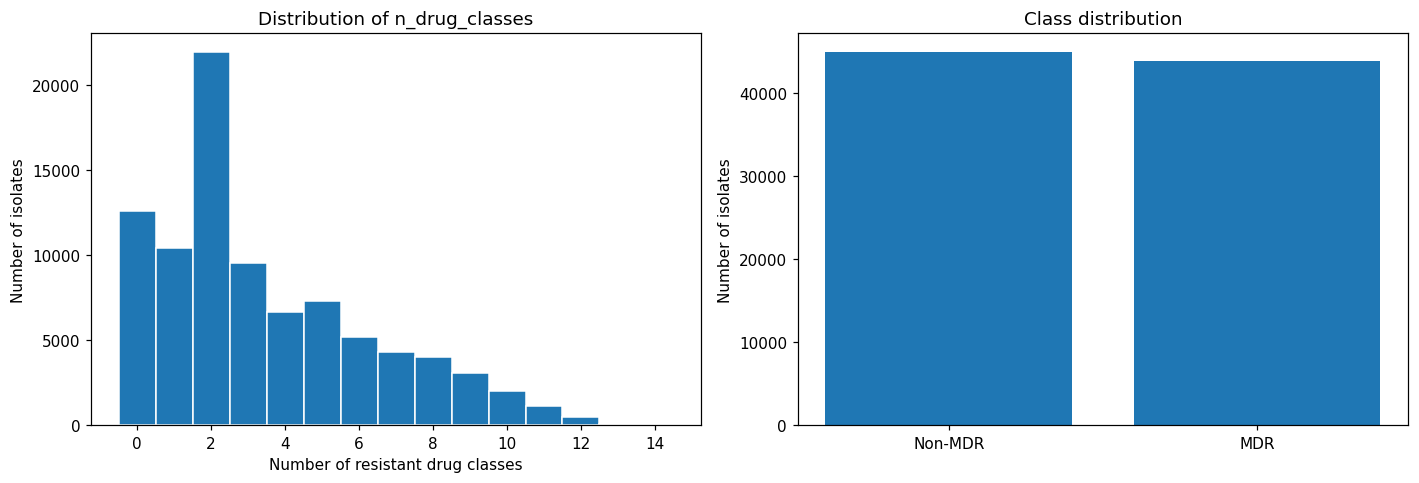

mdr_label
0    44958
1    43879
Name: count, dtype: int64
MDR prevalence: 0.494


In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(
    encoded["n_drug_classes"],
    bins=np.arange(encoded["n_drug_classes"].min(), encoded["n_drug_classes"].max() + 2) - 0.5,
    edgecolor="white"
)
axes[0].set_xlabel("Number of resistant drug classes")
axes[0].set_ylabel("Number of isolates")
axes[0].set_title("Distribution of n_drug_classes")

class_counts = encoded["mdr_label"].value_counts().sort_index()
axes[1].bar(["Non-MDR", "MDR"], class_counts.values)
axes[1].set_ylabel("Number of isolates")
axes[1].set_title("Class distribution")

plt.tight_layout()
plt.show()

print(class_counts)
print("MDR prevalence:", round(encoded["mdr_label"].mean(), 3))

## 2.3 Evaluation strategy

The main classification metric is **F1**, because the task is not purely about accuracy:
both false-positive and false-negative MDR predictions matter.

ROC-AUC and PR-AUC are also reported to describe ranking performance, while accuracy,
precision and recall provide operational context.

For regression, the main selection metric is **MAE**, because it is directly interpretable
as the average error in predicted drug-class count. RMSE and R² are reported alongside it.

---
# 3 — Train / Validation / Test Split

Phase 1 produced an 80/20 split. For Assignment 2 we rebuild the modelling split as:

- **70% training**
- **15% validation**
- **15% test**

The split is stratified by a combined `organism_group + mdr_label` key. This preserves both
the MDR balance and the organism composition across the three sets.

The test set is frozen after this section.

In [49]:
non_feature_cols = ["BioSample", "n_drug_classes", "mdr_label"]

X = encoded.drop(columns=non_feature_cols).copy()
y_class = encoded["mdr_label"].astype(int).copy()
y_reg = encoded["n_drug_classes"].astype(float).copy()

strat_key = (
    clean["organism_group"].astype(str)
    + "_"
    + clean["mdr_label"].astype(str)
)

X_temp, X_test, y_class_temp, y_class_test, y_reg_temp, y_reg_test, strat_temp, strat_test = train_test_split(
    X, y_class, y_reg, strat_key,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=strat_key
)

X_train, X_val, y_class_train, y_class_val, y_reg_train, y_reg_val = train_test_split(
    X_temp, y_class_temp, y_reg_temp,
    test_size=(0.15 / 0.85),
    random_state=RANDOM_STATE,
    stratify=strat_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (62185, 236)
Validation: (13326, 236)
Test: (13326, 236)


In [50]:
split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "N": [len(y_class_train), len(y_class_val), len(y_class_test)],
    "MDR rate": [
        y_class_train.mean(),
        y_class_val.mean(),
        y_class_test.mean()
    ]
})
display(split_summary.round(3))

# Confirm no isolate appears in more than one split.
train_ids = set(clean.loc[X_train.index, "BioSample"])
val_ids = set(clean.loc[X_val.index, "BioSample"])
test_ids = set(clean.loc[X_test.index, "BioSample"])

print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test      :", len(train_ids & test_ids))
print("Validation ∩ Test :", len(val_ids & test_ids))

,Split,N,MDR rate
0,Train,62185,0.494
1,Validation,13326,0.494
2,Test,13326,0.494


Train ∩ Validation: 0
Train ∩ Test      : 0
Validation ∩ Test : 0


### 3.1 Leakage control

All transformations that learn parameters from the data are fitted using the training
set only. In particular, the continuous variables are standardised using training-set
means and standard deviations.

The test set is not used for model selection, hyperparameter tuning, feature selection,
or early stopping.

In [51]:
numeric_cols = ["year", "n_virulence_genes", "n_stress_genes"]

scaler = StandardScaler().fit(X_train[numeric_cols])

X_train_s = X_train.copy()
X_val_s = X_val.copy()
X_test_s = X_test.copy()

for frame in (X_train_s, X_val_s, X_test_s):
    frame[numeric_cols] = scaler.transform(frame[numeric_cols])

print("Training-set scaling check:")
display(X_train_s[numeric_cols].describe().round(2))

Training-set scaling check:


,year,n_virulence_genes,n_stress_genes
count,62185.00,62185.00,62185.00
mean,0.00,0.00,0.00
std,1.00,1.00,1.00
min,-3.61,-1.12,-0.80
25%,-0.84,-0.97,-0.64
50%,0.20,-0.08,-0.31
75%,0.89,0.74,0.01
max,1.59,2.90,6.26


---
# 4 — Classification — Model Selection and Baselines

The candidate models deliberately span different modelling assumptions:

| Model | Role |
|---|---|
| Logistic Regression | Simple, interpretable linear baseline |
| Random Forest | Strong non-linear tree baseline for mixed tabular features |
| HistGradientBoosting | Efficient gradient boosting for structured/tabular data |
| MLP | Neural-network comparison for tabular data |

The purpose of this stage is **model selection using the validation set**, not final testing.

In [52]:
candidate_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    "MLP (Neural Net)": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=300,
        random_state=RANDOM_STATE,
        early_stopping=True
    ),
}

def classification_metrics(model, X_eval, y_eval, prefix="Val"):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)[:, 1]
    return {
        f"{prefix} Accuracy": accuracy_score(y_eval, pred),
        f"{prefix} Precision": precision_score(y_eval, pred),
        f"{prefix} Recall": recall_score(y_eval, pred),
        f"{prefix} F1": f1_score(y_eval, pred),
        f"{prefix} ROC-AUC": roc_auc_score(y_eval, proba),
        f"{prefix} PR-AUC": average_precision_score(y_eval, proba),
    }

baseline_results = []
fitted_baseline = {}

for name, model in candidate_models.items():
    start = time.time()
    model.fit(X_train_s, y_class_train)
    elapsed = time.time() - start
    fitted_baseline[name] = model

    row = {"Model": name, "Train time (s)": round(elapsed, 1)}
    row.update(classification_metrics(model, X_val_s, y_class_val, "Val"))
    baseline_results.append(row)

baseline_df = (
    pd.DataFrame(baseline_results)
    .sort_values("Val F1", ascending=False)
    .reset_index(drop=True)
)

display(baseline_df.round(3))

,Model,Train time (s),Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC,Val PR-AUC
0,Random Forest,20.9,0.890,0.912,0.860,0.885,0.958,0.961
1,MLP (Neural Net),23.8,0.880,0.911,0.838,0.873,0.952,0.957
2,Hist Gradient Boosting,11.1,0.877,0.911,0.833,0.870,0.950,0.956
3,Logistic Regression,6.7,0.853,0.881,0.813,0.846,0.934,0.941


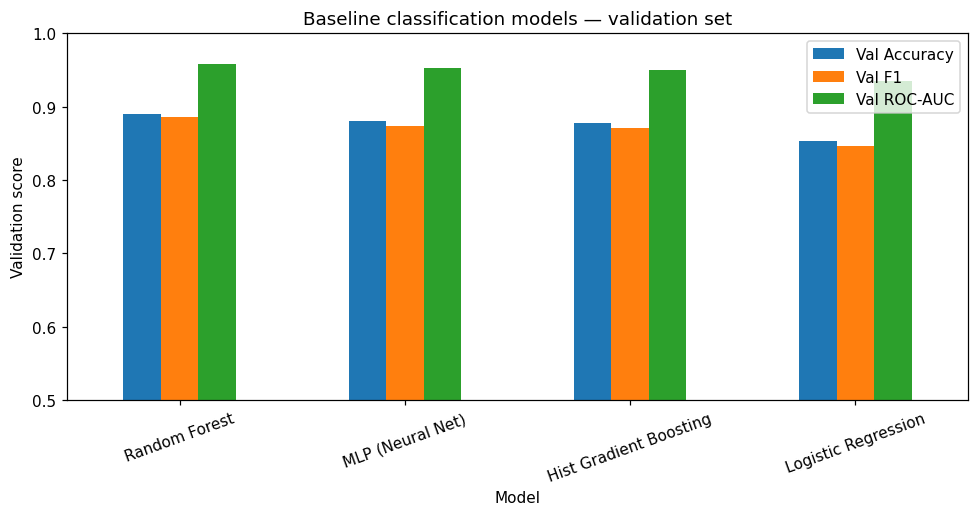

In [53]:
fig, ax = plt.subplots(figsize=(9, 4.8))
baseline_df.set_index("Model")[["Val Accuracy", "Val F1", "Val ROC-AUC"]].plot(
    kind="bar", ax=ax
)
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("Validation score")
ax.set_title("Baseline classification models — validation set")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 4.1 Interpretation

At this stage, Random Forest, HistGradientBoosting and the MLP are expected to be
competitive, with Logistic Regression serving as the interpretable reference point.

The important rule is:

> **No test-set ranking is performed here.**

The validation results determine which models deserve further tuning.

---
# 5 — Classification — Hyperparameter Tuning

The tuning budget is focused on the strongest tree-based baselines.




## 5.1 RandomizedsearchCV - Random Forest

`RandomizedSearchCV` uses cross-validation inside the **training set only**. The external validation set remains untouched during the search and is used afterward to compare the tuned candidates.

The search is intentionally modest so that the notebook remains practical to rerun.

In [54]:
rf_param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=8,
    cv=3,
    scoring="f1",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

start = time.time()
rf_search.fit(X_train_s, y_class_train)
print("Random Forest tuning time:", round(time.time() - start, 1), "s")
print("Best parameters:", rf_search.best_params_)
print("Best CV F1:", round(rf_search.best_score_, 3))

rf_tuned = rf_search.best_estimator_
rf_tuned_val = classification_metrics(rf_tuned, X_val_s, y_class_val, "Val")
print("Validation F1:", round(rf_tuned_val["Val F1"], 3))
print("Validation ROC-AUC:", round(rf_tuned_val["Val ROC-AUC"], 3))

Random Forest tuning time: 534.5 s
Best parameters: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
Best CV F1: 0.874
Validation F1: 0.88
Validation ROC-AUC: 0.956


## 5.2 RandomizedsearchCV - HistGradientBoostingClassifier

In [55]:
hgb_param_dist = {
    "max_iter": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "learning_rate": [0.05, 0.1, 0.2],
    "l2_regularization": [0, 0.5, 1.0],
}

hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    param_distributions=hgb_param_dist,
    n_iter=8,
    cv=3,
    scoring="f1",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

start = time.time()
hgb_search.fit(X_train_s, y_class_train)
print("HistGradientBoosting tuning time:", round(time.time() - start, 1), "s")
print("Best parameters:", hgb_search.best_params_)
print("Best CV F1:", round(hgb_search.best_score_, 3))

hgb_tuned = hgb_search.best_estimator_
hgb_tuned_val = classification_metrics(hgb_tuned, X_val_s, y_class_val, "Val")
print("Validation F1:", round(hgb_tuned_val["Val F1"], 3))
print("Validation ROC-AUC:", round(hgb_tuned_val["Val ROC-AUC"], 3))

HistGradientBoosting tuning time: 205.4 s
Best parameters: {'max_iter': 200, 'max_depth': 10, 'learning_rate': 0.2, 'l2_regularization': 0}
Best CV F1: 0.877
Validation F1: 0.882
Validation ROC-AUC: 0.958


## 5.3 XGBoost and CatBoost

These models are included as additional gradient-boosting comparisons. They are evaluated
on the **same training and validation split** as the scikit-learn models.

If the packages are unavailable, the notebook continues without them and reports which
models were skipped.

In [56]:
# In Google Colab, uncomment the following line if the packages are not already installed:
!pip -q install xgboost catboost

optional_models = {}

try:
    import xgboost as xgb

    optional_models["XGBoost"] = xgb.XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
except ImportError:
    print("XGBoost is not installed; it will be omitted.")

try:
    from catboost import CatBoostClassifier

    optional_models["CatBoost"] = CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.1,
        random_state=RANDOM_STATE,
        verbose=False
    )
except ImportError:
    print("CatBoost is not installed; it will be omitted.")

optional_fitted = {}
optional_validation = []

for name, model in optional_models.items():
    start = time.time()
    model.fit(X_train_s, y_class_train)
    optional_fitted[name] = model
    elapsed = time.time() - start

    row = {"Model": name, "Train time (s)": round(elapsed, 1)}
    row.update(classification_metrics(model, X_val_s, y_class_val, "Val"))
    optional_validation.append(row)

optional_val_df = pd.DataFrame(optional_validation)

if len(optional_val_df):
    display(optional_val_df.sort_values("Val F1", ascending=False).round(3))
else:
    print("No optional boosting models were available.")

CatBoost is not installed; it will be omitted.


,Model,Train time (s),Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC,Val PR-AUC
0,XGBoost,6.0,0.877,0.911,0.833,0.87,0.949,0.955


## 5.4 Validation comparison after tuning

The final classification candidates are now compared **only on validation performance**.

The model selected below is the model with the highest validation F1. This decision is
made before the test set is touched.

In [57]:
final_candidates = {
    "Logistic Regression": fitted_baseline["Logistic Regression"],
    "Random Forest (untuned)": fitted_baseline["Random Forest"],
    "Random Forest (tuned)": rf_tuned,
    "Hist Gradient Boosting (untuned)": fitted_baseline["Hist Gradient Boosting"],
    "Hist Gradient Boosting (tuned)": hgb_tuned,
    "MLP (Neural Net)": fitted_baseline["MLP (Neural Net)"],
}

final_validation_rows = []

for name, model in final_candidates.items():
    row = {"Model": name}
    row.update(classification_metrics(model, X_val_s, y_class_val, "Val"))
    final_validation_rows.append(row)

for name, model in optional_fitted.items():
    row = {"Model": name}
    row.update(classification_metrics(model, X_val_s, y_class_val, "Val"))
    final_validation_rows.append(row)

validation_comparison = (
    pd.DataFrame(final_validation_rows)
    .sort_values("Val F1", ascending=False)
    .reset_index(drop=True)
)

display(validation_comparison.round(3))

,Model,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC,Val PR-AUC
0,Random Forest (untuned),0.890,0.912,0.860,0.885,0.958,0.961
1,Hist Gradient Boosting (tuned),0.888,0.921,0.846,0.882,0.958,0.962
2,Random Forest (tuned),0.886,0.919,0.844,0.880,0.956,0.960
3,MLP (Neural Net),0.880,0.911,0.838,0.873,0.952,0.957
4,Hist Gradient Boosting (untuned),0.877,0.911,0.833,0.870,0.950,0.956
5,XGBoost,0.877,0.911,0.833,0.870,0.949,0.955
6,Logistic Regression,0.853,0.881,0.813,0.846,0.934,0.941


---
# 6 — Classification — Final Model Selection

The **validation set** is used to choose the final classification model.

This is deliberately separated from the test-set evaluation:

1. Train candidate models.
2. Tune selected candidates.
3. Compare candidates on validation F1.
4. Select the final model.
5. **Lock the choice.**
6. Only then evaluate on the held-out test set.

In [58]:
selected_model_name = validation_comparison.iloc[0]["Model"]
selected_model = final_candidates.get(selected_model_name, optional_fitted.get(selected_model_name))

if selected_model is None:
    raise RuntimeError("Selected model could not be recovered from the fitted model dictionary.")

print("Selected model based on validation F1:", selected_model_name)
print("Validation F1:", round(validation_comparison.iloc[0]["Val F1"], 3))
print("The test set remains locked until Section 7.")

Selected model based on validation F1: Random Forest (untuned)
Validation F1: 0.885
The test set remains locked until Section 7.


### 6.1 Model-selection decision

The model named above is now **locked as the primary classification model**.

The test set will be used only to estimate the generalisation performance of this
pre-selected model and to provide a transparent comparison of the other finalised
candidates.

---
# 7 — Classification — Final Test Evaluation

The test set is evaluated once after model selection.

The test ranking is reported for transparency, but **it is not used to change the
selected model**.

In [59]:
test_models = final_candidates.copy()
test_models.update(optional_fitted)

test_results = []

for name, model in test_models.items():
    row = {"Model": name}
    row.update(classification_metrics(model, X_test_s, y_class_test, "Test"))
    test_results.append(row)

test_df = (
    pd.DataFrame(test_results)
    .sort_values("Test F1", ascending=False)
    .reset_index(drop=True)
)

display(test_df.round(3))

selected_test_row = test_df.loc[test_df["Model"] == selected_model_name].iloc[0]
print(f"Locked model: {selected_model_name}")
print(f"Test accuracy: {selected_test_row['Test Accuracy']:.3f}")
print(f"Test F1:       {selected_test_row['Test F1']:.3f}")
print(f"Test ROC-AUC:  {selected_test_row['Test ROC-AUC']:.3f}")

,Model,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test PR-AUC
0,Random Forest (untuned),0.887,0.908,0.859,0.883,0.957,0.961
1,Hist Gradient Boosting (tuned),0.883,0.914,0.842,0.877,0.956,0.961
2,Random Forest (tuned),0.881,0.914,0.838,0.875,0.955,0.960
3,MLP (Neural Net),0.876,0.909,0.833,0.869,0.951,0.956
4,Hist Gradient Boosting (untuned),0.874,0.907,0.829,0.866,0.950,0.955
5,XGBoost,0.870,0.904,0.826,0.863,0.948,0.954
6,Logistic Regression,0.852,0.880,0.810,0.844,0.930,0.938


Locked model: Random Forest (untuned)
Test accuracy: 0.887
Test F1:       0.883
Test ROC-AUC:  0.957


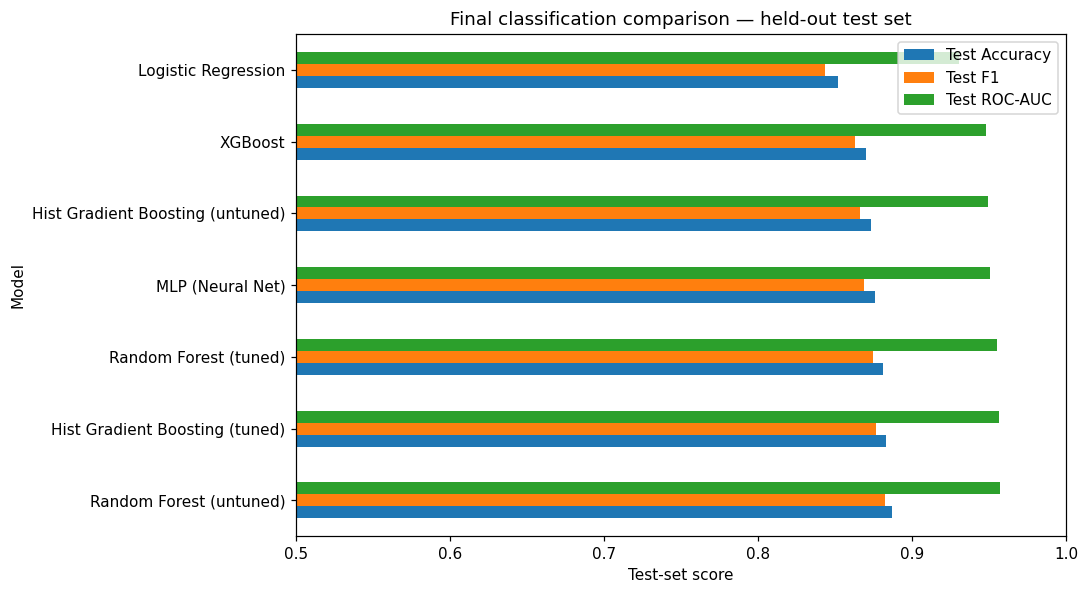

In [60]:
fig, ax = plt.subplots(figsize=(10, 5.5))
test_df.set_index("Model")[["Test Accuracy", "Test F1", "Test ROC-AUC"]].plot(
    kind="barh", ax=ax
)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Test-set score")
ax.set_title("Final classification comparison — held-out test set")
plt.tight_layout()
plt.show()

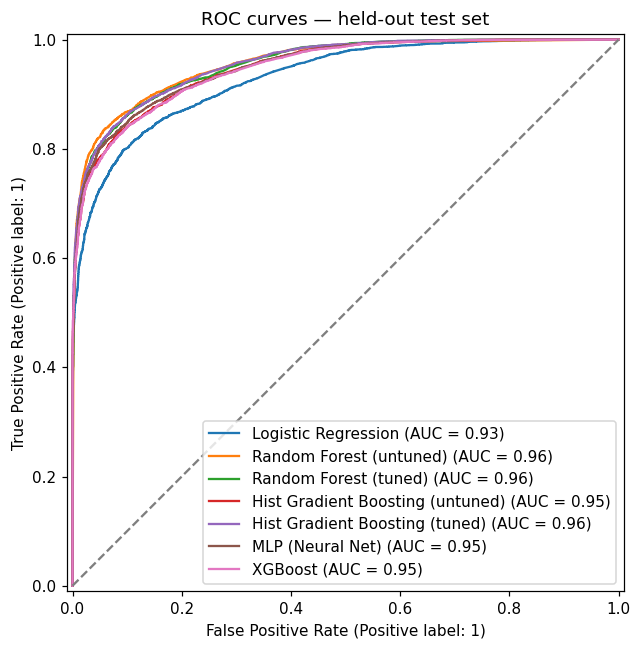

In [61]:
fig, ax = plt.subplots(figsize=(7, 6))

for name, model in test_models.items():
    RocCurveDisplay.from_estimator(
        model, X_test_s, y_class_test, ax=ax, name=name
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
ax.set_title("ROC curves — held-out test set")
plt.tight_layout()
plt.show()

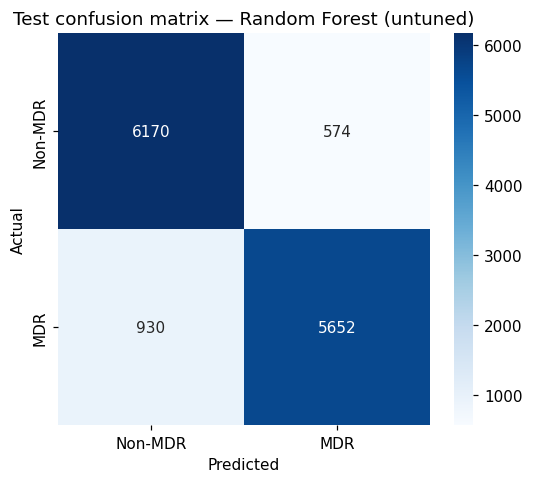

              precision    recall  f1-score   support

     Non-MDR       0.87      0.91      0.89      6744
         MDR       0.91      0.86      0.88      6582

    accuracy                           0.89     13326
   macro avg       0.89      0.89      0.89     13326
weighted avg       0.89      0.89      0.89     13326



In [62]:
# Confusion matrix for the VALIDATION-SELECTED model.
best_pred = selected_model.predict(X_test_s)

cm = confusion_matrix(y_class_test, best_pred)

fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=ax,
    xticklabels=["Non-MDR", "MDR"],
    yticklabels=["Non-MDR", "MDR"]
)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Test confusion matrix — {selected_model_name}")
plt.tight_layout()
plt.show()

print(classification_report(
    y_class_test,
    best_pred,
    target_names=["Non-MDR", "MDR"]
))

### 7.1 Error analysis

For the primary model, inspect the false positives and false negatives rather than
reporting only aggregate metrics. In this project, a false negative MDR prediction
means an isolate with resistance risk may be missed, while a false positive represents
an isolate that may be unnecessarily flagged for confirmatory testing.

Because the genotype-derived target itself over-calls MDR relative to AST, these errors
should not be interpreted as direct AST errors.

In [63]:
error_analysis = clean.loc[X_test.index, ["BioSample", "organism_group", "host_category", "isolation_type"]].copy()
error_analysis["actual_mdr"] = y_class_test.values
error_analysis["predicted_mdr"] = best_pred
error_analysis["error_type"] = np.select(
    [
        (error_analysis["actual_mdr"] == 0) & (error_analysis["predicted_mdr"] == 1),
        (error_analysis["actual_mdr"] == 1) & (error_analysis["predicted_mdr"] == 0),
    ],
    ["False positive", "False negative"],
    default="Correct"
)

display(
    error_analysis["error_type"]
    .value_counts()
    .rename_axis("Outcome")
    .to_frame("Count")
)

,Count
Outcome,
Correct,11822
False negative,930
False positive,574


---
# 8 — Classification — Interpretability

Performance alone does not answer the biological question. We therefore examine which
features the selected model relies on.

Where a model exposes native feature importance, that is used. Otherwise permutation
importance is calculated on the **validation set**, keeping interpretation separate from
the final test evaluation.

Importance method: native feature_importances_


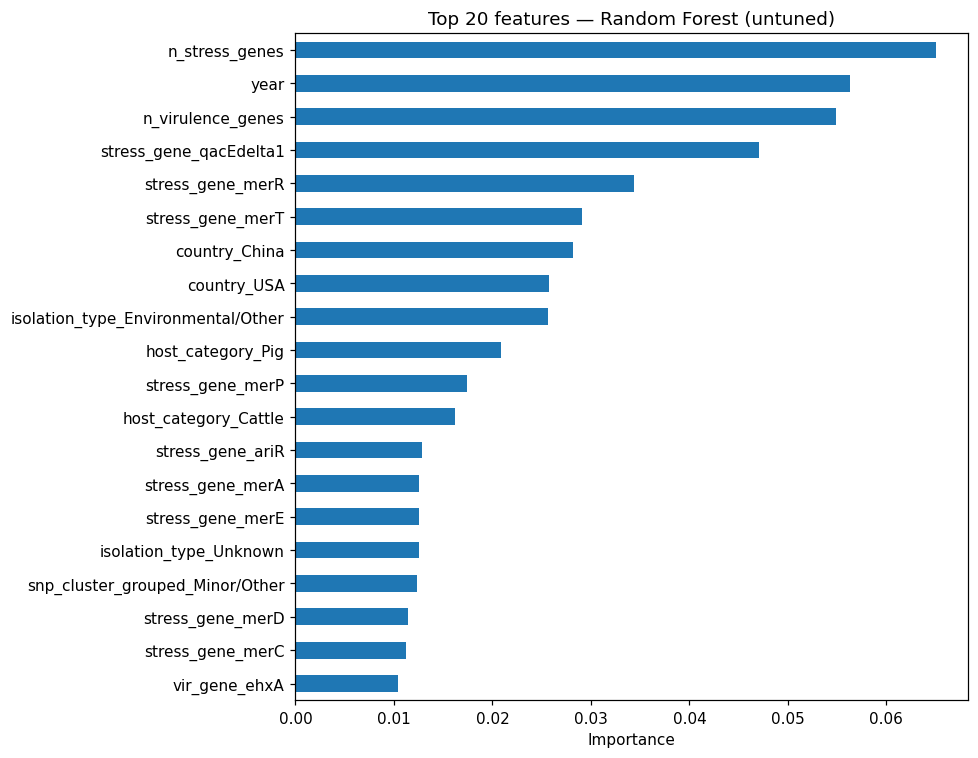

,Importance
n_stress_genes,0.0650
year,0.0563
n_virulence_genes,0.0549
stress_gene_qacEdelta1,0.0471
stress_gene_merR,0.0344
stress_gene_merT,0.0291
country_China,0.0281
country_USA,0.0257
isolation_type_Environmental/Other,0.0256
host_category_Pig,0.0208


In [64]:
feature_names = X_train_s.columns

if hasattr(selected_model, "feature_importances_"):
    importances = pd.Series(
        selected_model.feature_importances_,
        index=feature_names
    )
    importance_method = "native feature_importances_"
elif hasattr(selected_model, "coef_"):
    coef = np.asarray(selected_model.coef_)
    importances = pd.Series(np.abs(coef).ravel(), index=feature_names)
    importance_method = "absolute model coefficients"
else:
    perm = permutation_importance(
        selected_model,
        X_val_s,
        y_class_val,
        scoring="f1",
        n_repeats=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    importances = pd.Series(
        perm.importances_mean,
        index=feature_names
    )
    importance_method = "validation-set permutation importance"

print("Importance method:", importance_method)

top_20 = importances.sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(9, 7))
top_20.sort_values().plot(kind="barh", ax=ax)
ax.set_xlabel("Importance")
ax.set_title(f"Top 20 features — {selected_model_name}")
plt.tight_layout()
plt.show()

display(top_20.to_frame("Importance").round(4))

,Grouped importance
individual stress genes (top 50),0.2742
individual virulence genes (top 100),0.2618
country,0.0865
n_stress_genes,0.0650
year,0.0563
n_virulence_genes,0.0549
SNP cluster,0.0546
host_category,0.0477
isolation_type,0.0426
sample_source_detail,0.0305


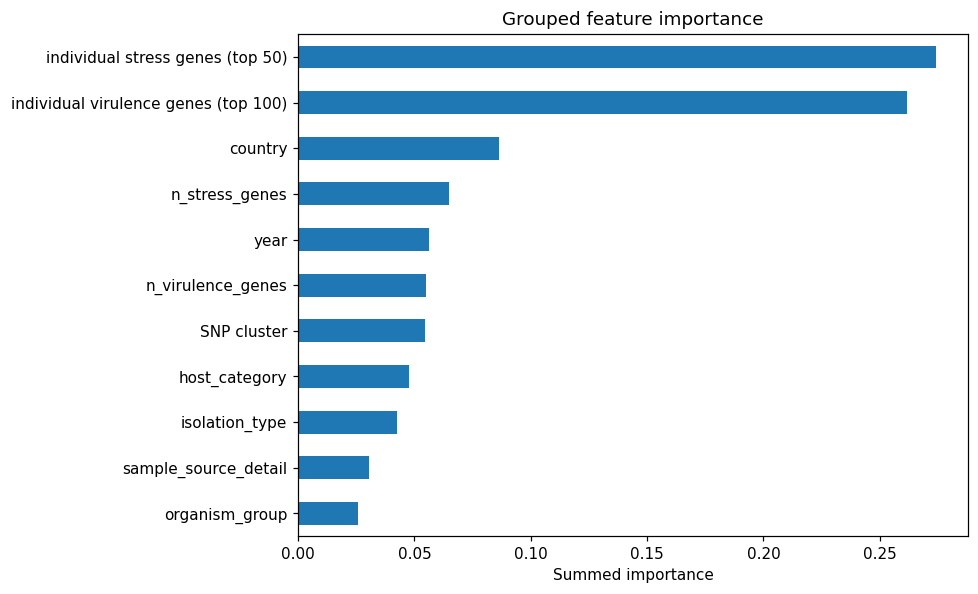

In [65]:
def feature_group(col):
    if col.startswith("vir_gene_"):
        return "individual virulence genes (top 100)"
    if col.startswith("stress_gene_"):
        return "individual stress genes (top 50)"
    if col.startswith("snp_cluster_grouped_"):
        return "SNP cluster"
    if col in ("n_virulence_genes", "n_stress_genes", "year"):
        return col
    for prefix in [
        "organism_group_", "host_category_", "isolation_type_",
        "sample_source_detail_", "country_"
    ]:
        if col.startswith(prefix):
            return prefix.rstrip("_")
    return col

grouped_importance = (
    importances.groupby(feature_group)
    .sum()
    .sort_values(ascending=False)
)

display(grouped_importance.to_frame("Grouped importance").round(4))

fig, ax = plt.subplots(figsize=(9, 5.5))
grouped_importance.head(12).sort_values().plot(kind="barh", ax=ax)
ax.set_xlabel("Summed importance")
ax.set_title("Grouped feature importance")
plt.tight_layout()
plt.show()

### 8.1 Biological interpretation

In phase 1, we showed that:

- individual stress genes were slightly more important as a group than individual virulence genes;
- `n_stress_genes` and `n_virulence_genes` as simple counts were much closer together;
- therefore **gene identity contains information that aggregate gene counts do not**.
In phase 1, we asked whether *how many* genes an isolate carries is associated with resistance. Here we investigate whether *which genes* are present helps
classification.

---
# 9 —Regression — `n_drug_classes`

The binary MDR target compresses resistance burden into a threshold. A second analysis
therefore predicts `n_drug_classes` directly.

The same fixed train/validation/test split is used so that the regression experiment
does not introduce another random partition.

In [66]:
reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Hist Gradient Boosting Regressor": HistGradientBoostingRegressor(
        random_state=RANDOM_STATE
    ),
    "MLP Regressor": MLPRegressor(
        hidden_layer_sizes=(64, 32),
        max_iter=300,
        random_state=RANDOM_STATE,
        early_stopping=True
    ),
}

reg_validation_rows = []
fitted_reg = {}

for name, model in reg_models.items():
    start = time.time()
    model.fit(X_train_s, y_reg_train)
    elapsed = time.time() - start
    fitted_reg[name] = model

    pred = model.predict(X_val_s)
    reg_validation_rows.append({
        "Model": name,
        "Val MAE": mean_absolute_error(y_reg_val, pred),
        "Val RMSE": mean_squared_error(y_reg_val, pred) ** 0.5,
        "Val R2": r2_score(y_reg_val, pred),
        "Train time (s)": round(elapsed, 1),
    })

reg_validation_df = (
    pd.DataFrame(reg_validation_rows)
    .sort_values("Val MAE")
    .reset_index(drop=True)
)

display(reg_validation_df.round(3))

,Model,Val MAE,Val RMSE,Val R2,Train time (s)
0,Random Forest Regressor,0.624,1.016,0.877,146.3
1,MLP Regressor,0.751,1.097,0.857,19.5
2,Hist Gradient Boosting Regressor,0.808,1.146,0.844,10.2
3,Linear Regression,1.004,1.378,0.774,0.9


### 9.1 Regression model selection

The final regression model is selected using **validation MAE**, where lower is better.
The held-out test set is not used to choose the regressor.

In [67]:
selected_reg_name = reg_validation_df.iloc[0]["Model"]
selected_reg = fitted_reg[selected_reg_name]

print("Selected regression model:", selected_reg_name)
print("Validation MAE:", round(reg_validation_df.iloc[0]["Val MAE"], 3))

Selected regression model: Random Forest Regressor
Validation MAE: 0.624


In [68]:
reg_test_rows = []

for name, model in fitted_reg.items():
    pred = model.predict(X_test_s)
    reg_test_rows.append({
        "Model": name,
        "Test MAE": mean_absolute_error(y_reg_test, pred),
        "Test RMSE": mean_squared_error(y_reg_test, pred) ** 0.5,
        "Test R2": r2_score(y_reg_test, pred),
    })

reg_test_df = (
    pd.DataFrame(reg_test_rows)
    .sort_values("Test MAE")
    .reset_index(drop=True)
)

display(reg_test_df.round(3))

selected_reg_test = reg_test_df.loc[
    reg_test_df["Model"] == selected_reg_name
].iloc[0]

print(f"Locked regression model: {selected_reg_name}")
print(f"Test MAE: {selected_reg_test['Test MAE']:.3f}")
print(f"Test RMSE: {selected_reg_test['Test RMSE']:.3f}")
print(f"Test R2: {selected_reg_test['Test R2']:.3f}")

,Model,Test MAE,Test RMSE,Test R2
0,Random Forest Regressor,0.620,1.012,0.876
1,MLP Regressor,0.754,1.098,0.855
2,Hist Gradient Boosting Regressor,0.810,1.142,0.843
3,Linear Regression,1.010,1.377,0.771


Locked regression model: Random Forest Regressor
Test MAE: 0.620
Test RMSE: 1.012
Test R2: 0.876


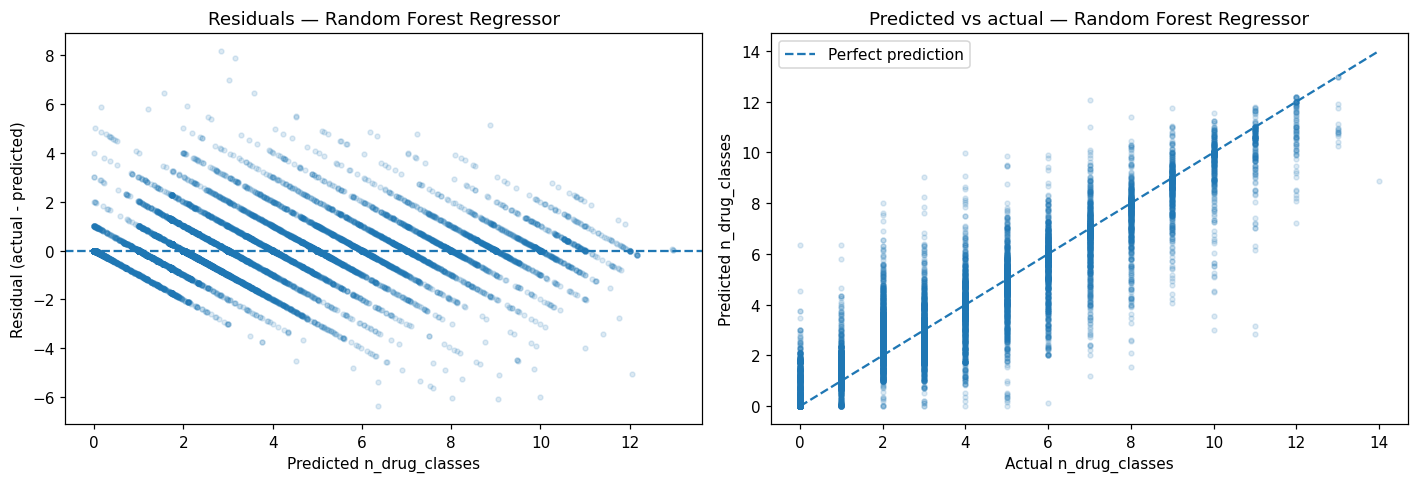

In [69]:
reg_pred = selected_reg.predict(X_test_s)
residuals = y_reg_test.values - reg_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(reg_pred, residuals, alpha=0.15, s=10 color='#4C72B0')
axes[0].axhline(0, color='red', linestyle="--")
axes[0].set_xlabel("Predicted n_drug_classes")
axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title(f"Residuals — {selected_reg_name}")

axes[1].scatter(y_reg_test, reg_pred, alpha=0.15, s=10, color='#55A868')
axes[1].plot([0, 14], [0, 14], color='red', linestyle="--", label="Perfect prediction")
axes[1].set_xlabel("Actual n_drug_classes")
axes[1].set_ylabel("Predicted n_drug_classes")
axes[1].set_title(f"Predicted vs actual — {selected_reg_name}")
axes[1].legend()

plt.tight_layout()
plt.show()



---
# 10 — Gene Co-occurrence Network

The graph analysis answers two different questions and they are kept separate:

1. **Descriptive question:** which genes co-occur most strongly in the study population?
2. **Predictive question:** does graph-derived information improve prediction?

The descriptive graph may use the full modelling population because it is exploratory and
does not feed a predictive model.

For the predictive graph feature, however, the graph is rebuilt from **training isolates only**
to prevent test-set information entering the feature.

### 10.1 Build the gene co-occurrence graph

An edge connects two genes if they ever appear together in the same isolate, weighted by how many isolates that pair co-occurs in.

In [70]:
import networkx as nx
from itertools import combinations
from collections import Counter

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    df_raw_graph = pd.read_csv(DATA_URL, engine="python", on_bad_lines="skip")

df_raw_graph.columns = [c.lstrip("#") for c in df_raw_graph.columns]
df_raw_graph = df_raw_graph.drop_duplicates(subset="BioSample", keep="first")

def parse_genes(gene_string):
    if pd.isna(gene_string):
        return []
    return [
        g.split("=")[0].strip()
        for g in str(gene_string).split(",")
        if g.split("=")[0].strip()
    ]

df_raw_graph["vir_gene_list"] = df_raw_graph["Virulence genotypes"].apply(parse_genes)
df_raw_graph["stress_gene_list"] = df_raw_graph["Stress genotypes"].apply(parse_genes)

pop = df_raw_graph[
    df_raw_graph["BioSample"].isin(clean["BioSample"])
].copy()

# Reuse the same 150-gene vocabulary represented in Phase 1.
vir_gene_columns = [c for c in encoded.columns if c.startswith("vir_gene_")]
stress_gene_columns = [c for c in encoded.columns if c.startswith("stress_gene_")]

top_vir_genes = [c.replace("vir_gene_", "", 1) for c in vir_gene_columns]
top_stress_genes = [c.replace("stress_gene_", "", 1) for c in stress_gene_columns]
top_genes = sorted(set(top_vir_genes + top_stress_genes))

isolate_gene_map = {}

for row in pop.itertuples(index=False):
    genes_here = sorted(set(
        [g for g in row.vir_gene_list if g in top_genes] +
        [g for g in row.stress_gene_list if g in top_genes]
    ))
    isolate_gene_map[row.BioSample] = genes_here

print("Population isolates:", len(pop))
print("Graph gene vocabulary:", len(top_genes))

Population isolates: 88837
Graph gene vocabulary: 150


## 10.2 Which genes are the biggest hubs?

In [72]:
# Descriptive full-population graph
edge_counter = Counter()

for genes_here in isolate_gene_map.values():
    for gene_a, gene_b in combinations(genes_here, 2):
        edge_counter[(gene_a, gene_b)] += 1

G = nx.Graph()
G.add_nodes_from(top_genes)

for (gene_a, gene_b), weight in edge_counter.items():
    G.add_edge(gene_a, gene_b, weight=weight)

weighted_degree = dict(G.degree(weight="weight"))
top_hubs = sorted(weighted_degree.items(), key=lambda x: -x[1])[:10]

print(f"Graph nodes: {G.number_of_nodes()}")
print(f"Graph edges: {G.number_of_edges()}")
print("Top 10 hubs by weighted co-occurrence degree: ")
for gene, weight in top_hubs:
    print(f"  {gene}: {weight:,}")

Graph nodes: 150
Graph edges: 8740
Top 10 hubs by weighted co-occurrence degree: 
  iroC: 1,122,000
  iroB: 1,114,783
  sinH: 1,011,402
  invA: 965,051
  golS: 962,890
  golT: 961,670
  pipA: 954,192
  avrA: 872,643
  stfA: 869,195
  hscC: 867,504


### 10.2.1 Biological interpretation of the hubs

The previous analysis identified hubs including genes such as `invA`, `avrA`, `iroB`
and `iroC`.

These should not automatically be interpreted as resistance co-selection hubs. Several
are near-core virulence genes in particular Salmonella lineages. Their high degree can
therefore partly reflect **organism structure**: genes common within a lineage will
naturally co-occur with many other genes carried by that lineage.

A useful extension is to construct organism-specific networks so that accessory-gene
co-occurrence is less dominated by core-genome structure.

## 10.3 Graph visualisation

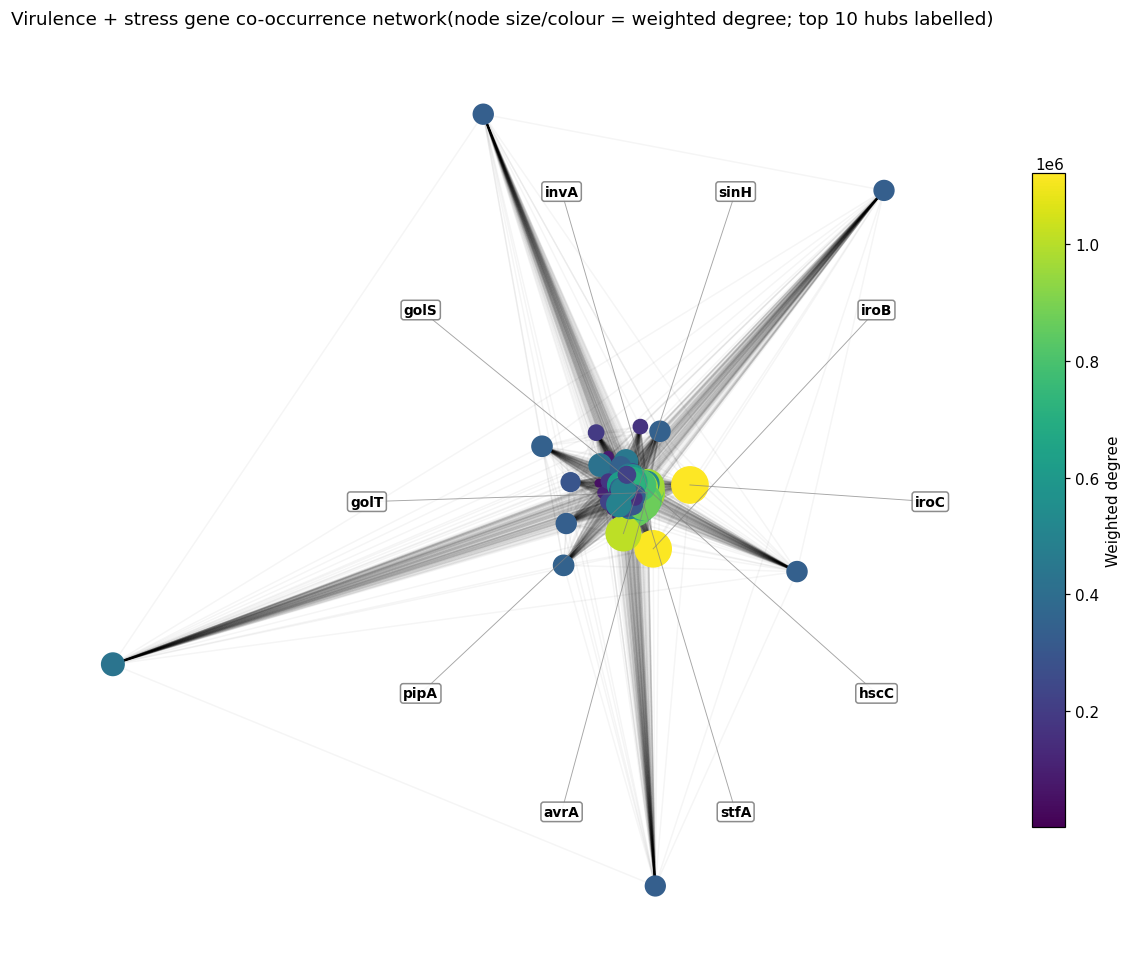

In [74]:
fig, ax = plt.subplots(figsize=(11, 9))

pos = nx.kamada_kawai_layout(G, weight="weight")

node_sizes = [weighted_degree[n] / 2000 for n in G.nodes()]
node_values = [weighted_degree[n] for n in G.nodes()]

nx.draw_networkx_edges(G, pos, alpha=0.04, ax=ax)
scatter = nx.draw_networkx_nodes(
    G, pos,
    node_size=node_sizes,
    node_color=node_values,
    cmap="viridis",
    ax=ax
)

top_hub_names = [gene for gene, _ in top_hubs]
hub_positions = np.array([pos[g] for g in top_hub_names])
centroid = hub_positions.mean(axis=0)

angles = np.linspace(0, 2 * np.pi, len(top_hub_names), endpoint=False)

for gene, angle in zip(top_hub_names, angles):
    label_x = centroid[0] + 0.55 * np.cos(angle)
    label_y = centroid[1] + 0.55 * np.sin(angle)
    node_x, node_y = pos[gene]

    ax.plot(
        [node_x, label_x],
        [node_y, label_y],
        color="gray",
        linewidth=0.6,
        alpha=0.7
    )
    ax.text(
        label_x, label_y, gene,
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        bbox=dict(
            boxstyle="round,pad=0.2",
            facecolor="white",
            edgecolor="gray",
            alpha=0.9
        )
    )

ax.set_title("Virulence + stress gene co-occurrence network"
    "(node size/colour = weighted degree; top 10 hubs labelled)"
)
ax.axis("off")
plt.colorbar(scatter, ax=ax, label="Weighted degree", shrink=0.7)
plt.tight_layout()
plt.show()

## 10.4 Predictive graph feature — training-only construction

The previous graph was descriptive.

For a predictive experiment, the graph must be learned from **training isolates only**.
The same fixed train/validation/test split used by the tabular models is therefore
reused here.

The graph feature is the mean weighted degree of the genes carried by an isolate.

In [75]:
# Map each BioSample to the already-frozen split.
biosample_split = {}

for idx in X_train.index:
    biosample_split[clean.loc[idx, "BioSample"]] = "train"
for idx in X_val.index:
    biosample_split[clean.loc[idx, "BioSample"]] = "val"
for idx in X_test.index:
    biosample_split[clean.loc[idx, "BioSample"]] = "test"

train_biosamples = {
    bio for bio, split in biosample_split.items() if split == "train"
}

# Build predictive graph using TRAINING isolates only.
train_edge_counter = Counter()

for bio_sample in train_biosamples:
    genes_here = isolate_gene_map.get(bio_sample, [])
    for gene_a, gene_b in combinations(genes_here, 2):
        train_edge_counter[(gene_a, gene_b)] += 1

G_train = nx.Graph()
G_train.add_nodes_from(top_genes)

for (gene_a, gene_b), weight in train_edge_counter.items():
    G_train.add_edge(gene_a, gene_b, weight=weight)

train_weighted_degree = dict(G_train.degree(weight="weight"))

def isolate_graph_score_from_train_graph(genes_here):
    if not genes_here:
        return 0.0
    return np.mean([
        train_weighted_degree.get(g, 0.0)
        for g in genes_here
    ])

graph_scores = pd.Series(
    {
        bio: isolate_graph_score_from_train_graph(isolate_gene_map.get(bio, []))
        for bio in biosample_split
    },
    name="graph_centrality_score"
)

encoded_graph = encoded.copy()
encoded_graph["graph_centrality_score"] = (
    encoded_graph["BioSample"].map(graph_scores).fillna(0.0)
)

print("Training-only graph edges:", G_train.number_of_edges())
print(
    "Correlation of training-derived graph score with n_drug_classes:",
    round(
        encoded_graph["graph_centrality_score"].corr(
            encoded_graph["n_drug_classes"]
        ),
        3
    )
)

Training-only graph edges: 8664
Correlation of training-derived graph score with n_drug_classes: -0.058


In [76]:
# Controlled validation comparison: identical model, identical split, one extra graph feature.
X_graph = encoded_graph.drop(columns=non_feature_cols)
X_graph_train = X_graph.loc[X_train.index].copy()
X_graph_val = X_graph.loc[X_val.index].copy()

graph_numeric_cols = numeric_cols + ["graph_centrality_score"]
graph_scaler = StandardScaler().fit(X_graph_train[graph_numeric_cols])

X_graph_train_s = X_graph_train.copy()
X_graph_val_s = X_graph_val.copy()

X_graph_train_s[graph_numeric_cols] = graph_scaler.transform(
    X_graph_train_s[graph_numeric_cols]
)
X_graph_val_s[graph_numeric_cols] = graph_scaler.transform(
    X_graph_val_s[graph_numeric_cols]
)

rf_without_graph = RandomForestClassifier(
    n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
)
rf_with_graph = RandomForestClassifier(
    n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
)

rf_without_graph.fit(X_train_s, y_class_train)
rf_with_graph.fit(X_graph_train_s, y_class_train)

pred_without = rf_without_graph.predict(X_val_s)
proba_without = rf_without_graph.predict_proba(X_val_s)[:, 1]

pred_with = rf_with_graph.predict(X_graph_val_s)
proba_with = rf_with_graph.predict_proba(X_graph_val_s)[:, 1]

graph_feature_comparison = pd.DataFrame({
    "Model": ["Without graph feature", "With training-derived graph feature"],
    "Validation F1": [
        f1_score(y_class_val, pred_without),
        f1_score(y_class_val, pred_with)
    ],
    "Validation ROC-AUC": [
        roc_auc_score(y_class_val, proba_without),
        roc_auc_score(y_class_val, proba_with)
    ]
})

display(graph_feature_comparison.round(3))

,Model,Validation F1,Validation ROC-AUC
0,Without graph feature,0.885,0.958
1,With training-derived graph feature,0.885,0.958


## 10.5 Interpretation


The graph feature makes no measurable difference (F1 and ROC-AUC identical to three decimal places), and this result is now confirmed using a training-only graph, so it cannot be attributed to the earlier leakage. The reason is straightforward: the model already has all 150 individual gene presence/absence flags directly available (Section from multi-hot encoding in Assignment 1). A single aggregate centrality summary of those same genes cannot add information a flexible model doesn't already have in finer-grained form — if anything, collapsing 150 binary signals into one scalar throws information away.
Therefore, adding a single graph-centrality score produced **no measurable improvement** over the individual gene features.

That negative result is useful:
> a single aggregate graph statistic can discard information that is already available to a flexible tabular model through the individual gene indicators.

This motivates the next experiment: a GNN can learn **relational representations** rather than compressing the entire graph into one scalar.

---
# 11 — Graph Neural Network

## 11.1 Motivation

The GNN asks a more specific question than the centrality experiment:

> **Does the pattern of relationships among genes add predictive information beyond
> knowing which genes are present?**

Each isolate is represented as a graph:

- **nodes** = genes carried by the isolate;
- **node identity** = learned gene embedding;
- **edges** = gene pairs that co-occur in the training population;
- **edge weight** = training-population co-occurrence count, transformed with `log1p`;
- **graph label** = genotype-derived `mdr_label`.

The GNN uses the same frozen train/validation/test isolate split as the tabular models.

In [87]:
# GNN dependencies are optional because the notebook should still run in environments
# without PyTorch Geometric.
#
# In Google Colab, uncomment if needed:
!pip -q install torch-geometric

try:
    import torch
    import torch.nn.functional as F
    from torch_geometric.data import Data
    from torch_geometric.loader import DataLoader
    from torch_geometric.nn import GCNConv, global_mean_pool, global_max_pool
    GNN_AVAILABLE = True
    print("PyTorch Geometric is available.")
except ImportError as exc:
    GNN_AVAILABLE = False
    print("PyTorch Geometric is not available.")
    print("GNN sections will be skipped until the package is installed.")
    print("Import error:", exc)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 852.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 7.7 MB/s eta 0:00:00
PyTorch Geometric is available.


## 11.2 Training-only graph construction

The descriptive graph above was built from all isolates.

For the GNN, that would be inappropriate because the edge weights would contain
information from validation and test isolates. Instead, `G_train` is used as the
population graph from which validation/test isolate subgraphs are extracted.

This means:

- training isolates contribute to the graph;
- validation/test isolates do **not** contribute to edge discovery or edge weights;
- the frozen tabular split is preserved.

In [88]:
if GNN_AVAILABLE:
    gene_to_idx = {gene: i for i, gene in enumerate(sorted(top_genes))}
    NUM_GENES = len(gene_to_idx)

    # Metadata features parallel the contextual variables used by the tabular models.
    meta_cols_categorical = [
        "host_category", "organism_group",
        "isolation_type", "country"
    ]

    meta_df = (
        clean.set_index("BioSample")[
            meta_cols_categorical + ["year"]
        ]
        .copy()
    )

    meta_encoded = pd.get_dummies(
        meta_df,
        columns=meta_cols_categorical,
        drop_first=False
    ).astype("float32")

    # Fit the year transformation using training isolates only.
    train_biosample_list = [
        clean.loc[idx, "BioSample"] for idx in X_train.index
    ]
    year_scaler_gnn = StandardScaler().fit(
        meta_encoded.loc[train_biosample_list, ["year"]]
    )
    meta_encoded.loc[:, ["year"]] = year_scaler_gnn.transform(
        meta_encoded[["year"]]
    )

    METADATA_DIM = meta_encoded.shape[1]
    print("Number of gene nodes in vocabulary:", NUM_GENES)
    print("Metadata dimensions:", METADATA_DIM)

Number of gene nodes in vocabulary: 150
Metadata dimensions: 26


In [89]:
if GNN_AVAILABLE:
    def make_isolate_graph(bio_sample):
        genes_here = isolate_gene_map.get(bio_sample, [])
        genes_here = [g for g in genes_here if g in gene_to_idx]

        if len(genes_here) == 0:
            return None

        local_idx = {g: i for i, g in enumerate(genes_here)}
        edge_pairs = []
        edge_weights = []

        for gene_a, gene_b in combinations(genes_here, 2):
            if G_train.has_edge(gene_a, gene_b):
                edge_pairs.append([local_idx[gene_a], local_idx[gene_b]])
                edge_weights.append(
                    np.log1p(G_train[gene_a][gene_b]["weight"])
                )

        if edge_pairs:
            edge_index = torch.tensor(
                edge_pairs, dtype=torch.long
            ).t().contiguous()
            edge_index = torch.cat(
                [edge_index, edge_index.flip(0)],
                dim=1
            )

            edge_weight = torch.tensor(
                edge_weights, dtype=torch.float32
            )
            edge_weight = torch.cat(
                [edge_weight, edge_weight],
                dim=0
            )
        else:
            # GCNConv can add self-loops; an empty edge list is therefore
            # still a valid single-node / disconnected-node graph.
            edge_index = torch.empty((2, 0), dtype=torch.long)
            edge_weight = torch.empty((0,), dtype=torch.float32)

        x = torch.tensor(
            [gene_to_idx[g] for g in genes_here],
            dtype=torch.long
        ).unsqueeze(1)

        label = int(clean.set_index("BioSample").loc[bio_sample, "mdr_label"])

        metadata = torch.tensor(
            meta_encoded.loc[bio_sample].values,
            dtype=torch.float32
        ).unsqueeze(0)

        return Data(
            x=x,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=torch.tensor([label], dtype=torch.long),
            metadata=metadata
        )

    split_biosamples = {
        "train": [
            clean.loc[idx, "BioSample"] for idx in X_train.index
        ],
        "val": [
            clean.loc[idx, "BioSample"] for idx in X_val.index
        ],
        "test": [
            clean.loc[idx, "BioSample"] for idx in X_test.index
        ]
    }

    graph_sets = {}
    for split_name, biosamples in split_biosamples.items():
        graph_sets[split_name] = [
            make_isolate_graph(bio)
            for bio in biosamples
        ]
        graph_sets[split_name] = [
            g for g in graph_sets[split_name] if g is not None
        ]

    print(
        "Graphs:",
        {k: len(v) for k, v in graph_sets.items()}
    )

    train_loader = DataLoader(
        graph_sets["train"], batch_size=64, shuffle=True
    )
    val_loader = DataLoader(
        graph_sets["val"], batch_size=64, shuffle=False
    )
    test_loader = DataLoader(
        graph_sets["test"], batch_size=64, shuffle=False
    )

Graphs: {'train': 54986, 'val': 11813, 'test': 11835}


## 11.3 GNN architecture

A two-layer GCN is deliberately kept small.

The model uses:

1. a learned embedding for gene identity;
2. two graph-convolution layers;
3. mean and max graph pooling;
4. the contextual metadata vector;
5. a two-class classifier.

Mean pooling captures the average graph representation, while max pooling preserves
strong signals from individual nodes.

In [90]:
if GNN_AVAILABLE:
    class GeneGCNWithMetadata(torch.nn.Module):
        def __init__(
            self,
            num_genes,
            metadata_dim,
            embedding_dim=16,
            hidden_dim=32
        ):
            super().__init__()

            self.embedding = torch.nn.Embedding(
                num_genes, embedding_dim
            )

            self.conv1 = GCNConv(
                embedding_dim, hidden_dim
            )
            self.conv2 = GCNConv(
                hidden_dim, hidden_dim
            )

            self.classifier = torch.nn.Sequential(
                torch.nn.Linear(
                    hidden_dim * 2 + metadata_dim,
                    hidden_dim
                ),
                torch.nn.ReLU(),
                torch.nn.Linear(hidden_dim, 2)
            )

        def forward(
            self,
            x,
            edge_index,
            edge_weight,
            batch,
            metadata
        ):
            x = self.embedding(x.squeeze(-1))

            x = F.relu(
                self.conv1(
                    x,
                    edge_index,
                    edge_weight=edge_weight
                )
            )

            x = F.relu(
                self.conv2(
                    x,
                    edge_index,
                    edge_weight=edge_weight
                )
            )

            mean_x = global_mean_pool(x, batch)
            max_x = global_max_pool(x, batch)

            graph_x = torch.cat(
                [mean_x, max_x],
                dim=1
            )

            graph_x = torch.cat(
                [graph_x, metadata],
                dim=1
            )

            return self.classifier(graph_x)

Epoch 01 | train_loss=0.351 train_F1=0.840 | val_loss=0.322 val_F1=0.859
Epoch 02 | train_loss=0.314 train_F1=0.861 | val_loss=0.312 val_F1=0.856
Epoch 03 | train_loss=0.309 train_F1=0.861 | val_loss=0.309 val_F1=0.861
Epoch 04 | train_loss=0.306 train_F1=0.864 | val_loss=0.312 val_F1=0.865
Epoch 05 | train_loss=0.304 train_F1=0.864 | val_loss=0.306 val_F1=0.866
Epoch 06 | train_loss=0.303 train_F1=0.864 | val_loss=0.314 val_F1=0.845
Epoch 07 | train_loss=0.301 train_F1=0.866 | val_loss=0.296 val_F1=0.870
Epoch 08 | train_loss=0.300 train_F1=0.867 | val_loss=0.307 val_F1=0.870
Epoch 09 | train_loss=0.299 train_F1=0.868 | val_loss=0.300 val_F1=0.861
Epoch 10 | train_loss=0.298 train_F1=0.866 | val_loss=0.304 val_F1=0.868
Epoch 11 | train_loss=0.298 train_F1=0.866 | val_loss=0.304 val_F1=0.870
Epoch 12 | train_loss=0.298 train_F1=0.868 | val_loss=0.300 val_F1=0.869
Epoch 13 | train_loss=0.297 train_F1=0.868 | val_loss=0.304 val_F1=0.864
Epoch 14 | train_loss=0.296 train_F1=0.868 | val_lo

,Epoch,Train loss,Train F1,Val loss,Val F1
11,12,0.297657,0.867730,0.299918,0.868785
12,13,0.297049,0.867709,0.304268,0.863506
13,14,0.295632,0.868238,0.302968,0.864928
14,15,0.294958,0.867942,0.300824,0.863363
15,16,0.294746,0.868387,0.297401,0.868195


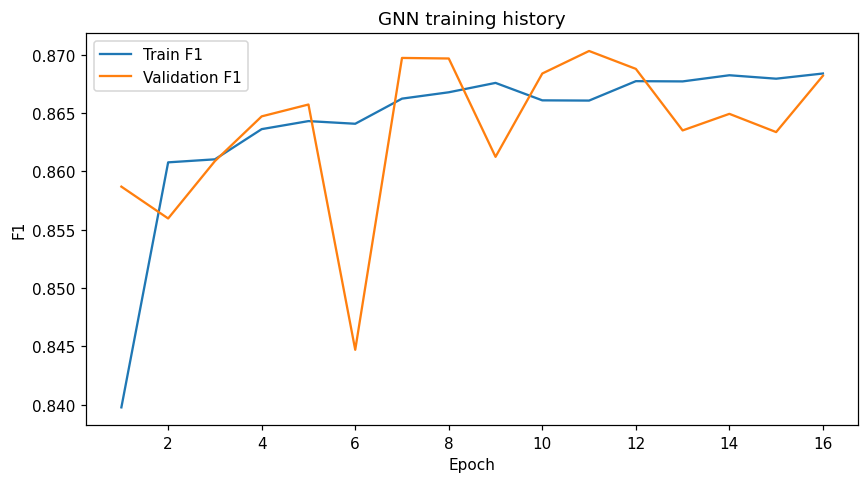

In [91]:
if GNN_AVAILABLE:
    torch.manual_seed(RANDOM_STATE)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RANDOM_STATE)

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    gnn_model = GeneGCNWithMetadata(
        num_genes=NUM_GENES,
        metadata_dim=METADATA_DIM,
        embedding_dim=16,
        hidden_dim=32
    ).to(device)

    optimizer_gnn = torch.optim.Adam(
        gnn_model.parameters(),
        lr=0.005,
        weight_decay=5e-4
    )

    criterion_gnn = torch.nn.CrossEntropyLoss()

    def run_gnn_epoch(loader, train=False):
        if train:
            gnn_model.train()
        else:
            gnn_model.eval()

        total_loss = 0.0
        all_preds = []
        all_labels = []

        with torch.set_grad_enabled(train):
            for batch in loader:
                batch = batch.to(device)

                if train:
                    optimizer_gnn.zero_grad()

                out = gnn_model(
                    batch.x,
                    batch.edge_index,
                    batch.edge_weight,
                    batch.batch,
                    batch.metadata
                )

                loss = criterion_gnn(
                    out, batch.y
                )

                if train:
                    loss.backward()
                    optimizer_gnn.step()

                total_loss += (
                    loss.item() * batch.num_graphs
                )

                all_preds.extend(
                    out.argmax(dim=1).detach().cpu().tolist()
                )
                all_labels.extend(
                    batch.y.detach().cpu().tolist()
                )

        return {
            "loss": total_loss / len(all_labels),
            "accuracy": accuracy_score(
                all_labels, all_preds
            ),
            "f1": f1_score(
                all_labels, all_preds
            )
        }

    best_val_f1_gnn = -np.inf
    patience = 5
    patience_counter = 0
    best_path = "best_gene_gcn_metadata.pt"

    history = []

    for epoch in range(1, 31):
        train_metrics = run_gnn_epoch(
            train_loader, train=True
        )
        val_metrics = run_gnn_epoch(
            val_loader, train=False
        )

        history.append({
            "Epoch": epoch,
            "Train loss": train_metrics["loss"],
            "Train F1": train_metrics["f1"],
            "Val loss": val_metrics["loss"],
            "Val F1": val_metrics["f1"]
        })

        print(
            f"Epoch {epoch:02d} | "
            f"train_loss={train_metrics['loss']:.3f} "
            f"train_F1={train_metrics['f1']:.3f} | "
            f"val_loss={val_metrics['loss']:.3f} "
            f"val_F1={val_metrics['f1']:.3f}"
        )

        if val_metrics["f1"] > best_val_f1_gnn:
            best_val_f1_gnn = val_metrics["f1"]
            patience_counter = 0
            torch.save(
                gnn_model.state_dict(),
                best_path
            )
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(
                    f"Early stopping at epoch {epoch}"
                )
                break

    gnn_model.load_state_dict(
        torch.load(
            best_path,
            map_location=device
        )
    )

    history_df = pd.DataFrame(history)
    display(history_df.tail())

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(
        history_df["Epoch"],
        history_df["Train F1"],
        label="Train F1"
    )
    ax.plot(
        history_df["Epoch"],
        history_df["Val F1"],
        label="Validation F1"
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("F1")
    ax.set_title("GNN training history")
    ax.legend()
    plt.tight_layout()
    plt.show()

In [92]:
if GNN_AVAILABLE:
    gnn_test_metrics = run_gnn_epoch(
        test_loader, train=False
    )

    print(
        f"GNN test accuracy: {gnn_test_metrics['accuracy']:.3f}"
    )
    print(
        f"GNN test F1:       {gnn_test_metrics['f1']:.3f}"
    )
else:
    gnn_test_metrics = None
    print("GNN test evaluation skipped because PyTorch Geometric is unavailable.")

GNN test accuracy: 0.862
GNN test F1:       0.869


## 11.7 Gene-set ablation

The GNN can appear to perform well simply because it learns gene identities.

To test whether **graph structure itself** contributes information, the ablation model uses:

- the same gene embeddings;
- the same metadata;
- the same training/validation/test graphs;
- the same optimiser and early stopping strategy;

but **does not perform graph message passing**.

The comparison is therefore:

> **GNN with graph structure vs. gene-set model without message passing**

In [93]:
if GNN_AVAILABLE:
    class GeneSetNN(torch.nn.Module):
        def __init__(
            self,
            num_genes,
            metadata_dim,
            embedding_dim=16,
            hidden_dim=32
        ):
            super().__init__()

            self.embedding = torch.nn.Embedding(
                num_genes, embedding_dim
            )

            self.project = torch.nn.Linear(
                embedding_dim, hidden_dim
            )

            self.classifier = torch.nn.Sequential(
                torch.nn.Linear(
                    hidden_dim + metadata_dim,
                    hidden_dim
                ),
                torch.nn.ReLU(),
                torch.nn.Linear(hidden_dim, 2)
            )

        def forward(
            self,
            x,
            edge_index,
            edge_weight,
            batch,
            metadata
        ):
            x = self.embedding(x.squeeze(-1))
            x = F.relu(self.project(x))
            x = global_mean_pool(x, batch)

            x = torch.cat(
                [x, metadata],
                dim=1
            )

            return self.classifier(x)

    torch.manual_seed(RANDOM_STATE)

    gene_set_model = GeneSetNN(
        num_genes=NUM_GENES,
        metadata_dim=METADATA_DIM
    ).to(device)

    gene_set_optimizer = torch.optim.Adam(
        gene_set_model.parameters(),
        lr=0.005,
        weight_decay=5e-4
    )

    def run_gene_set_epoch(loader, train=False):
        gene_set_model.train() if train else gene_set_model.eval()

        total_loss = 0.0
        all_preds = []
        all_labels = []

        with torch.set_grad_enabled(train):
            for batch in loader:
                batch = batch.to(device)

                if train:
                    gene_set_optimizer.zero_grad()

                out = gene_set_model(
                    batch.x,
                    batch.edge_index,
                    batch.edge_weight,
                    batch.batch,
                    batch.metadata
                )

                loss = criterion_gnn(
                    out, batch.y
                )

                if train:
                    loss.backward()
                    gene_set_optimizer.step()

                total_loss += loss.item() * batch.num_graphs
                all_preds.extend(
                    out.argmax(dim=1).detach().cpu().tolist()
                )
                all_labels.extend(
                    batch.y.detach().cpu().tolist()
                )

        return {
            "loss": total_loss / len(all_labels),
            "accuracy": accuracy_score(
                all_labels, all_preds
            ),
            "f1": f1_score(
                all_labels, all_preds
            )
        }

    best_val_f1_set = -np.inf
    patience_counter = 0
    best_set_path = "best_gene_set_ablation.pt"

    for epoch in range(1, 31):
        train_m = run_gene_set_epoch(
            train_loader, train=True
        )
        val_m = run_gene_set_epoch(
            val_loader, train=False
        )

        if val_m["f1"] > best_val_f1_set:
            best_val_f1_set = val_m["f1"]
            patience_counter = 0
            torch.save(
                gene_set_model.state_dict(),
                best_set_path
            )
        else:
            patience_counter += 1
            if patience_counter >= 5:
                break

    gene_set_model.load_state_dict(
        torch.load(
            best_set_path,
            map_location=device
        )
    )

    gene_set_test_metrics = run_gene_set_epoch(
        test_loader, train=False
    )

    print(
        f"Gene-set-only test F1: {gene_set_test_metrics['f1']:.3f}"
    )
    print(
        f"Full GNN test F1:      {gnn_test_metrics['f1']:.3f}"
    )
else:
    gene_set_test_metrics = None

Gene-set-only test F1: 0.865
Full GNN test F1:      0.869


## 11.8 GNN vs Random Forest on the same test isolates

The final comparison uses exactly the same test BioSamples for the GNN and the
validation-selected Random Forest.

This comparison does **not** allow the GNN to select the overall winning model;
it simply quantifies whether the graph-based approach generalises better or worse
than the strongest conventional tabular approach.

In [94]:
if GNN_AVAILABLE:
    # The GNN test set follows the frozen X_test BioSamples.
    rf_test_pred_same = selected_model.predict(X_test_s)

    gnn_vs_rf = pd.DataFrame({
        "Approach": [
            "Selected Random Forest / tabular model",
            "GNN + metadata",
            "Gene-set ablation + metadata"
        ],
        "Test F1": [
            f1_score(y_class_test, rf_test_pred_same),
            gnn_test_metrics["f1"],
            gene_set_test_metrics["f1"]
        ],
        "Test Accuracy": [
            accuracy_score(y_class_test, rf_test_pred_same),
            gnn_test_metrics["accuracy"],
            gene_set_test_metrics["accuracy"]
        ]
    })

    display(gnn_vs_rf.round(3))
else:
    gnn_vs_rf = None
    print("GNN comparison skipped because PyTorch Geometric is unavailable.")

,Approach,Test F1,Test Accuracy
0,Selected Random Forest / tabular model,0.883,0.887
1,GNN + metadata,0.869,0.862
2,Gene-set ablation + metadata,0.865,0.857


### Interpretation of the GNN experiment

The GNN should be interpreted as an **experimental extension**, not automatically as
a superior model.

Three outcomes are informative:

1. **GNN > gene-set ablation:** graph structure appears to contribute information.
2. **GNN ≈ gene-set ablation:** the learned gene identities may explain most of the signal.
3. **GNN < Random Forest:** this would demonstrate that a more complex relational model
   does not necessarily outperform a strong tabular baseline for this dataset.

The previous run suggested that the graph-based models were close to the tabular baseline,
but the earlier implementation used an independently generated split. The redrafted
workflow above removes that problem by reusing the frozen tabular split.

---
# 12 — Overall Results

This section brings the separate experiments back together.

The purpose is not to select a model retrospectively from the test results. The purpose
is to summarise the decisions already made using the validation set and then report the
held-out performance.

In [95]:
# Classification summary for the validation-selected model
classification_summary = pd.DataFrame({
    "Task": ["Classification"],
    "Selected model": [selected_model_name],
    "Selection metric": ["Validation F1"],
    "Validation score": [
        validation_comparison.loc[
            validation_comparison["Model"] == selected_model_name,
            "Val F1"
        ].iloc[0]
    ],
    "Test accuracy": [selected_test_row["Test Accuracy"]],
    "Test F1": [selected_test_row["Test F1"]],
    "Test ROC-AUC": [selected_test_row["Test ROC-AUC"]],
})

regression_summary = pd.DataFrame({
    "Task": ["Regression"],
    "Selected model": [selected_reg_name],
    "Selection metric": ["Validation MAE"],
    "Validation score": [
        reg_validation_df.loc[
            reg_validation_df["Model"] == selected_reg_name,
            "Val MAE"
        ].iloc[0]
    ],
    "Test MAE": [selected_reg_test["Test MAE"]],
    "Test RMSE": [selected_reg_test["Test RMSE"]],
    "Test R2": [selected_reg_test["Test R2"]],
})

display(classification_summary.round(3))
display(regression_summary.round(3))

if gnn_vs_rf is not None:
    print("Graph-model comparison:")
    display(gnn_vs_rf.round(3))

,Task,Selected model,Selection metric,Validation score,Test accuracy,Test F1,Test ROC-AUC
0,Classification,Random Forest (untuned),Validation F1,0.885,0.887,0.883,0.957


,Task,Selected model,Selection metric,Validation score,Test MAE,Test RMSE,Test R2
0,Regression,Random Forest Regressor,Validation MAE,0.624,0.62,1.012,0.876


Graph-model comparison:


,Approach,Test F1,Test Accuracy
0,Selected Random Forest / tabular model,0.883,0.887
1,GNN + metadata,0.869,0.862
2,Gene-set ablation + metadata,0.865,0.857


### 12.1 Key findings

- The genotype-derived MDR target is a useful **screening/risk proxy**, but AST validation shows that it over-calls MDR relative to phenotype.
- Random Forest was the strongest conventional classification baseline in the previous run, with approximately **0.887 accuracy, 0.883 F1 and 0.957 ROC-AUC** on the held-out test set.
- Random Forest Regressor was the strongest regression model in the previous run, with approximately **0.620 MAE and 0.876 R²** on the held-out test set.
- Individual stress and virulence gene identities were more informative than simple aggregate gene counts.
- The descriptive co-occurrence network was strongly influenced by near-core genes and organism structure.
- A single graph-centrality feature did not improve the tabular Random Forest in the previous run.
- The corrected GNN experiment should be interpreted using the results produced after rerunning the fixed-split implementation above.

---
# 13 — Conclusions

## 13.1 Main classification finding

The classification experiment evaluates whether genotype-derived features can distinguish
MDR from non-MDR isolates. The final model is selected using validation F1 and then evaluated
once on the held-out test set.

The previous run identified **Random Forest** as the strongest conventional model, achieving
approximately **88.7% test accuracy, 0.883 F1 and 0.957 ROC-AUC**.

The main result is therefore that the genotype-derived feature space contains substantial
predictive information about the MDR-risk proxy.

## 13.2 Regression finding

Predicting `n_drug_classes` provides a more granular measure of resistance burden than the
binary MDR threshold.

The previous run identified **Random Forest Regressor** as the strongest regressor, with
approximately **0.620 test MAE and 0.876 test R²**.

This suggests that the predictors contain substantial information not only about whether
an isolate crosses the MDR threshold, but also about the approximate number of resistant
drug classes.

## 13.3 Biological interpretation

Feature importance refined the Phase 1 findings.

Aggregate gene counts alone do not tell the whole story. In the previous run, individual
stress genes and individual virulence genes accounted for substantial grouped importance,
indicating that **gene identity** can be informative even when the corresponding total
gene count has a weak correlation with resistance.

## 13.4 AST validation caveat

The genotype-derived MDR target agreed with AST-derived MDR status in approximately **77.9%**
of the available validation isolates. The comparison showed high recall but substantially
lower precision.

Therefore, the models should be described as predicting **genotypic resistance risk**.
They are better framed as screening or triage tools that can identify isolates deserving
confirmatory laboratory testing than as replacements for phenotypic AST.

## 13.5 Gene co-occurrence network

The co-occurrence network identified highly connected genes, including SPI-1 and iroA-locus
genes among the major hubs.

However, high network centrality does not automatically imply resistance co-selection.
Near-core genes can become hubs simply because they occur broadly within particular organisms.
Organism-specific networks would provide a cleaner test of accessory-gene co-selection.

## 13.6 Graph-based prediction

A single graph-centrality feature did not improve the conventional Random Forest in the
previous analysis. This is a meaningful negative result because the model already receives
the individual gene indicators directly.

The GNN provides a stronger test of the graph hypothesis because it learns relational
representations through message passing. The corrected fixed-split GNN result should be
reported here after rerunning Section 11.

## 13.7 Limitations

1. The primary targets are genotype-derived rather than phenotype-confirmed.
2. AST coverage is limited.
3. The gene-to-drug-class mapping is a curated rule set rather than the official AMRFinderPlus
   reference catalogue.
4. `year` represents NCBI submission date rather than necessarily the true collection date.
5. The dataset contains sampling imbalance by host, organism, country and isolation type.
6. The co-occurrence graph combines core and accessory genes.
7. The GNN is sensitive to graph construction choices and requires careful control of information
   flow between train, validation and test isolates.
8. The 150-gene vocabulary was inherited from Phase 1, where top genes were selected before the
   Phase 2 split; this should be acknowledged as a limitation if strict feature-selection
   leakage control is required.

## 13.8 Future work

- Validate the genotype-derived target against a larger independent AST dataset.
- Build organism-specific and accessory-gene-focused co-occurrence networks.
- Investigate richer biological networks rather than population co-occurrence alone.
- Tune the GNN more systematically if graph structure provides evidence of additional signal.
- Evaluate the final models on an independent external cohort.
- Investigate calibration and threshold selection for practical screening use.

---
# 14 — Reproducibility and Saved Results

The following cell saves the principal Phase 2 result tables so that the notebook's
numerical results can be cited without manually copying values from the outputs.

In [96]:
# Save result tables generated during this notebook.
baseline_df.to_csv("phase2_classification_baselines.csv", index=False)
validation_comparison.to_csv("phase2_classification_validation_comparison.csv", index=False)
test_df.to_csv("phase2_classification_test_results.csv", index=False)
reg_validation_df.to_csv("phase2_regression_validation_results.csv", index=False)
reg_test_df.to_csv("phase2_regression_test_results.csv", index=False)
graph_feature_comparison.to_csv("phase2_graph_feature_validation_comparison.csv", index=False)

if gnn_vs_rf is not None:
    gnn_vs_rf.to_csv("phase2_gnn_comparison.csv", index=False)

print("Phase 2 result tables saved.")

Phase 2 result tables saved.
